# **IMPORTAÇÃO DAS BIBLIOTECAS**

In [174]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import shap
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay, auc
from sklearn.model_selection import cross_val_predict, StratifiedKFold, cross_validate, cross_val_score, RepeatedStratifiedKFold
from sklearn.metrics import recall_score, precision_score
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from statsmodels.stats.outliers_influence import variance_inflation_factor


# **CARREGAMENTO DOS DADOS**

In [175]:
nomes = ['num_identificacao', 'diagnostico', 'raio_media', 'textura_media', 'perimetro_media', 'area_media', 'suavidade_media', 'compacidade_media', 'concavidade_media', 'pontos_concavos_media', 'simetria_media', 'dimensao_fractal_media', 'raio_se', 'textura_se', 'perimetro_se', 'area_se', 'suavidade_se', 'compacidade_se', 'concavidade_se', 'pontos_concavos_se', 'simetria_se', 'dimensao_fractal_se', 'raio_worst', 'textura_worst', 'perimetro_worst', 'area_worst', 'suavidade_worst', 'compacidade_worst', 'concavidade_worst', 'pontos_concavos_worst', 'simetria_worst', 'dimensao_fractal_worst']

df = pd.read_csv('../data/wdbc.data', header=None, names=nomes)

# **CONFERÊNCIA DOS DADOS**

In [176]:
df.head()

,num_identificacao,diagnostico,raio_media,textura_media,perimetro_media,area_media,suavidade_media,compacidade_media,concavidade_media,pontos_concavos_media,...,raio_worst,textura_worst,perimetro_worst,area_worst,suavidade_worst,compacidade_worst,concavidade_worst,pontos_concavos_worst,simetria_worst,dimensao_fractal_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [177]:
df['diagnostico'].value_counts()

diagnostico
B    357
M    212
Name: count, dtype: int64

In [178]:
df.shape

(569, 32)

In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   num_identificacao       569 non-null    int64  
 1   diagnostico             569 non-null    object 
 2   raio_media              569 non-null    float64
 3   textura_media           569 non-null    float64
 4   perimetro_media         569 non-null    float64
 5   area_media              569 non-null    float64
 6   suavidade_media         569 non-null    float64
 7   compacidade_media       569 non-null    float64
 8   concavidade_media       569 non-null    float64
 9   pontos_concavos_media   569 non-null    float64
 10  simetria_media          569 non-null    float64
 11  dimensao_fractal_media  569 non-null    float64
 12  raio_se                 569 non-null    float64
 13  textura_se              569 non-null    float64
 14  perimetro_se            569 non-null    fl

# **PREPARAÇÃO DO ALVO E DAS VARIÁVEIS**

In [180]:
df['diagnostico'].value_counts()

diagnostico
B    357
M    212
Name: count, dtype: int64

In [181]:
df.drop(['num_identificacao'], axis=1, inplace=True)

In [182]:
df['diagnostico'] = df['diagnostico'].map({'M': 1, 'B': 0})

In [183]:
df['diagnostico'].value_counts()

diagnostico
0    357
1    212
Name: count, dtype: int64

In [184]:
X = df.drop('diagnostico', axis=1)
y = df['diagnostico']

LIMPANDO E PADRONIZANDO A VARIAVEL X

# **DISTRIBUIÇÃO DAS CLASSES**

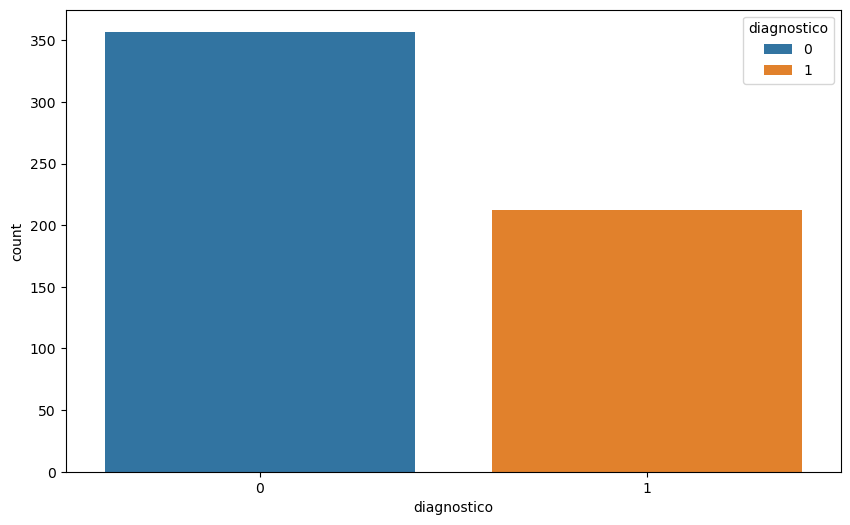

In [185]:
plt.figure(figsize=(10, 6))
sns.countplot(x='diagnostico', data=df, hue=y)
plt.xticks()
plt.show()

# **ANÁLISE EXPLORATÓRIA**

In [186]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
diagnostico,569.0,0.37,0.48,0.00,0.00,0.00,1.00,1.00
raio_media,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
textura_media,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
perimetro_media,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
area_media,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
suavidade_media,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
compacidade_media,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
concavidade_media,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
pontos_concavos_media,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
simetria_media,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30


In [187]:
df.groupby("diagnostico")[["area_worst", "concavidade_worst", "textura_worst"]].mean().round(2)

,area_worst,concavidade_worst,textura_worst
diagnostico,,,
0,558.90,0.17,23.52
1,1422.29,0.45,29.32


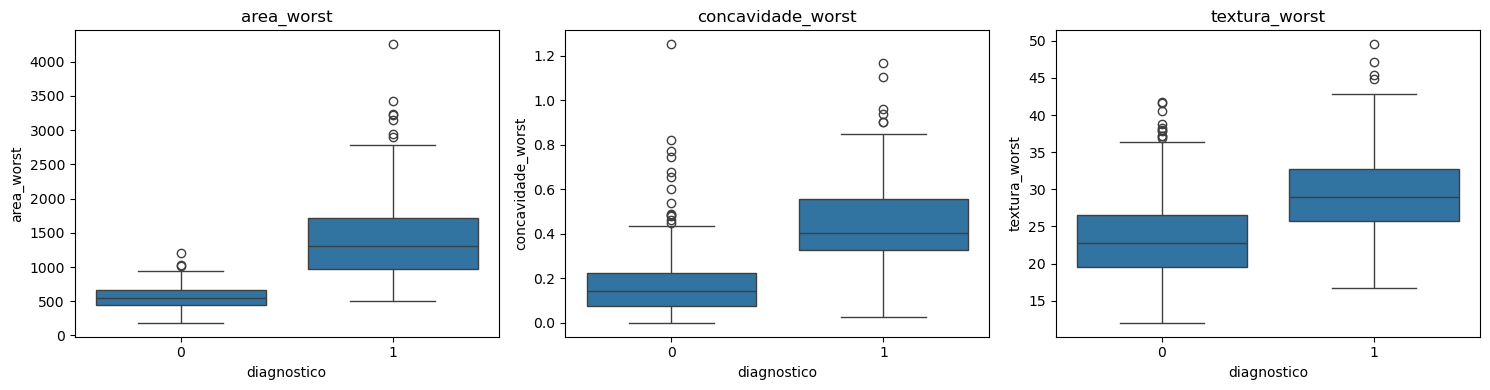

In [188]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["area_worst", "concavidade_worst", "textura_worst"]):
    sns.boxplot(data=df, x="diagnostico", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

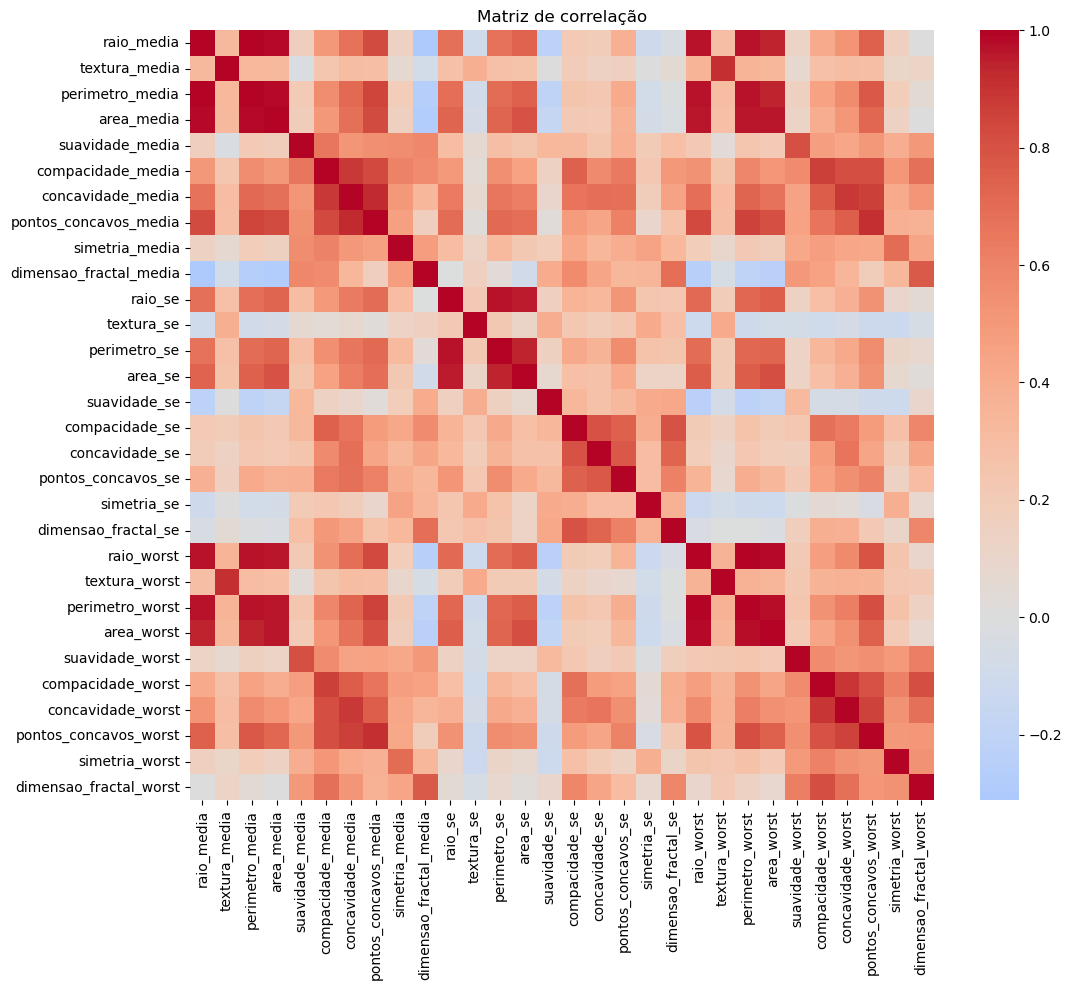

In [189]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.drop(columns=["diagnostico"]).corr(), cmap="coolwarm", center=0)
plt.title("Matriz de correlação")
plt.show()

# **OBSERVAÇÕES: ANÁLISE EXPLORATÓRIA**

- Os dados estão completos (569 linhas, sem valores ausentes) e 37% dos casos são malignos.
- As variáveis têm escalas muito diferentes (area_worst chega a 4254, suavidade fica perto de 0,1), o que justifica o escalonamento na regressão logística.
- Variáveis como area_se e raio_se têm caudas longas, com poucos tumores muito grandes. Os valores foram mantidos por serem casos reais.
- area_worst e concavidade_worst separam bem benignos e malignos, e a textura_worst separa menos, com mais sobreposição.

# **DIVISÃO TREINO E TESTE**

In [190]:
X = df.drop('diagnostico', axis=1)
y = df['diagnostico']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

# **REGRESSÃO LOGÍSTICA**
**CRIANDO O PRIMEIRO MODELO E TREINANDO O MODELO**

In [191]:
modelo_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

modelo_lr.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

## **AVALIAÇÃO NO TESTE COM LIMIAR 0,5 (PADRÃO)**

**FAZENDO A PREDIÇÃO DO MODELO LOGISTIC**

In [192]:
y_pred_lr = modelo_lr.predict(X_test)

**DESEMPENHO DO MODELO**

In [193]:
print("Acurácia:", accuracy_score(y_test, y_pred_lr))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_lr))
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred_lr))

Acurácia: 0.9707602339181286

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       107
           1       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171


Matriz de Confusão:
[[106   1]
 [  4  60]]


**DISPLAY DE MATRIX DE CONFUSAO - LOGISTIC REGRESSION**

Matriz de Confusao
[[106   1]
 [  4  60]]


Text(0.5, 1.0, 'Matriz de Confusao - Regressão Logistica')

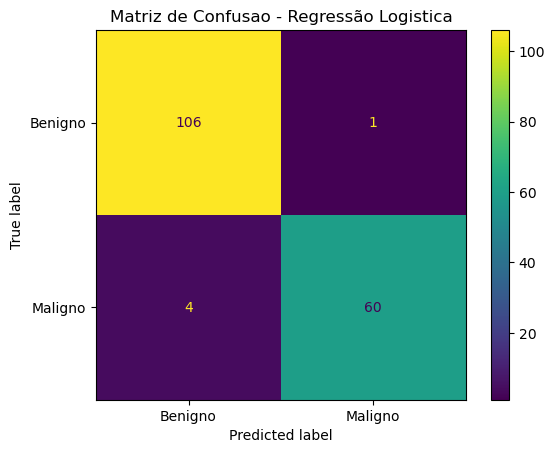

In [194]:
matrix_lr = confusion_matrix(y_test, y_pred_lr)

print("Matriz de Confusao")
print(matrix_lr)


disp = ConfusionMatrixDisplay(
    confusion_matrix=matrix_lr,
    display_labels=['Benigno', 'Maligno']
)

disp.plot()
plt.title("Matriz de Confusao - Regressão Logistica")

## **COEFICIENTES E ODDS RATIO**

**O QUE É ODDS** (chance): a razão entre a probabilidade de acontecer e a de não acontecer.

Probabilidade de 50% de ser maligno → odds de 1 (1 para 1)

Probabilidade de 75% → odds de 3 (3 para 1)

Probabilidade de 20% → odds de 0,25 (1 para 4)

====================================================================================================


**O ODDS RATIO** diz quantas vezes essas odds se multiplicam quando a variável aumenta em 1 unidade, com as outras mantidas fixas.

Como ler:

Maior que > 1: a variável aumenta a chance de maligno. Um odds ratio de 2 significa que a chance dobra.

Igual a == 1: não tem efeito (coeficiente zero).

Menor que < 1: diminui a chance de maligno. Um odds ratio de 0,5 significa que a chance cai pela metade.

Odds ratio: “quantas vezes multiplica a chance”.

In [195]:
clf = modelo_lr.named_steps["clf"]      # a LogisticRegression dentro do Pipeline
coef = clf.coef_[0]

tabela = pd.DataFrame({
    "Variavel": X_train.columns,
    "Coeficiente": coef,
    "Odds_ratio": np.exp(coef),
}).sort_values("Coeficiente", key=abs, ascending=False)

tabela.head(10)

,Variavel,Coeficiente,Odds_ratio
21,textura_worst,1.384327,3.992136
10,raio_se,1.205130,3.337193
28,simetria_worst,1.085744,2.961642
13,area_se,0.912114,2.489579
15,compacidade_se,-0.904630,0.404692
23,area_worst,0.876082,2.401472
7,pontos_concavos_media,0.853924,2.348845
20,raio_worst,0.845014,2.328010
26,concavidade_worst,0.832548,2.299170
6,concavidade_media,0.805938,2.238795


**VISUALIZANDO A IMPORTANCIA DAS 10 VARIAVEIS DE ACORDO COM SUA COEFIENCIA**

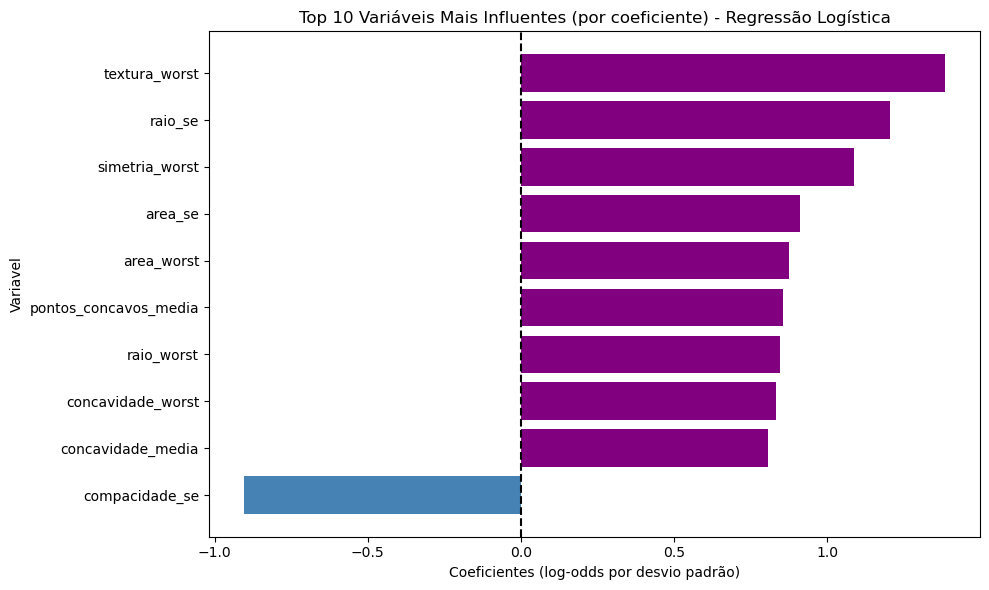

In [196]:
top10 = tabela.sort_values(
    by='Coeficiente',
    key=abs,
    ascending=False
).head(10)


top10 = top10.sort_values(by='Coeficiente')

positivos = top10['Coeficiente'] > 0

plt.figure(figsize=(10, 6))

plt.barh(
    top10['Variavel'],
    top10['Coeficiente'],
    color=['purple' if x > 0 else 'steelblue'
           for x in top10['Coeficiente']]
)

plt.axvline(0, color='black', linestyle = '--')

plt.xlabel('Coeficientes (log-odds por desvio padrão)')
plt.ylabel('Variavel')
plt.title("Top 10 Variáveis Mais Influentes (por coeficiente) - Regressão Logística")
plt.tight_layout()
plt.show()

## **SHAP DA REGRESSÃO LOGÍSTICA**

In [197]:
# Separa as duas etapas do Pipeline: o escalonador e o classificador (a regressão logística)
scaler = modelo_lr.named_steps["scaler"]
clf = modelo_lr.named_steps["clf"]

# Aplica o escalonamento nos dados de treino e de teste, como o modelo faz por dentro.
# O resultado do transform é um array, então volto para DataFrame para manter os nomes das colunas.
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# Cria o explicador para modelos lineares. Ele recebe o classificador e os dados de treino escalonados,
# que servem como referência (o "valor médio" a partir do qual cada variável empurra a previsão).
explainer = shap.LinearExplainer(clf, X_train_s) # Regressão logística (LinearExplainer): Usa log-odds, a mesma escala dos coeficientes.

# Calcula o valor SHAP de cada variável para cada paciente do teste:
# quanto aquela variável empurrou a previsão para maligno (positivo) ou benigno (negativo)
shap_lr = explainer(X_test_s)

Background dataset has 398 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=398 when initializing the masker.


### **GRÁFICO DE BARRAS DO SHAPE**

**Mostra a importância média de cada variável, ou seja, o quanto ela desloca a previsão em média. É a visão comparável com a permutation e o feature_importances_.**

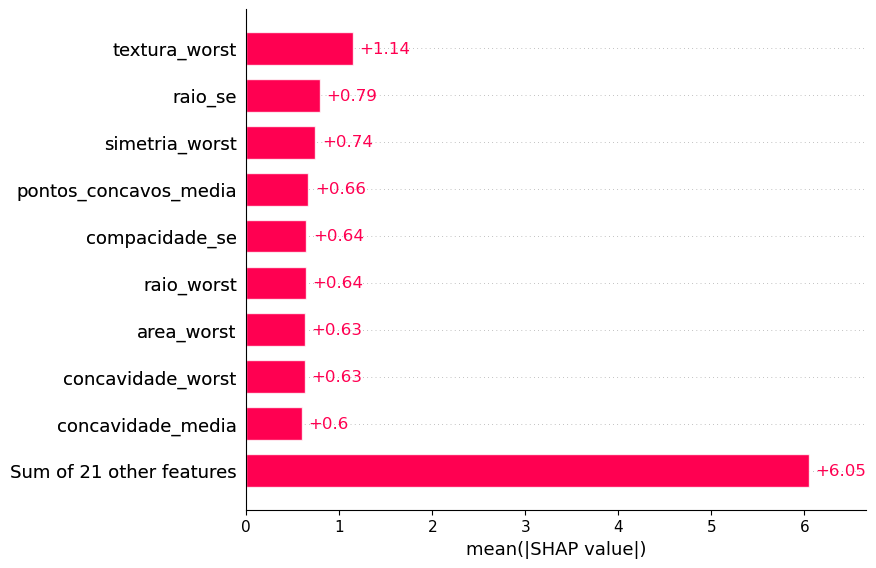

In [198]:
shap.plots.bar(shap_lr, max_display=10)

### **GRÁFICO DE PONTOS DO SHAPE**

**Cada ponto é um paciente. Pontos à direita empurram para maligno (classe 1) e à esquerda para benigno. A cor mostra se o valor da variável é alto (vermelho) ou baixo (azul).**

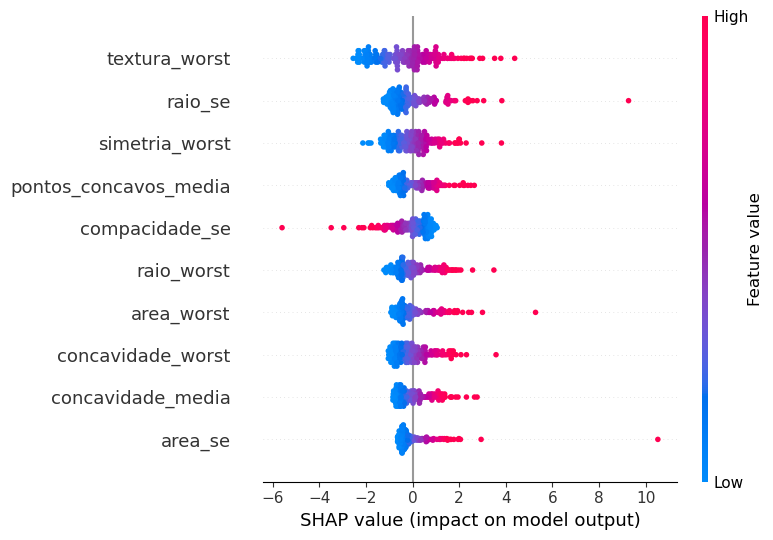

In [199]:
shap.summary_plot(shap_lr, X_test_s, max_display=10)

#### **OBSERVAÇÕES: SHAP DA REGRESSÃO LOGÍSTICA**

- A textura_worst é a variável que mais desloca a previsão (1,14), bem acima das demais. Da 2ª à 9ª posição os valores ficam entre 0,60 e 0,79, quase empatados, então a ordem entre elas não é confiável.
- As 21 variáveis restantes somam 6,05, mais que qualquer variável isolada: o peso da regressão logística está espalhado por muitas medidas, o que bate com a colinearidade vista antes.
- No gráfico de pontos, valores altos de textura, raio, área, simetria, concavidade e pontos côncavos (vermelho, à direita) empurram a previsão para maligno, coerente com os odds ratio acima de 1.
- A compacidade_se faz o contrário: valores altos empurram para benigno. Como ela é correlacionada com as variáveis de concavidade e tamanho, o sinal negativo provavelmente compensa essas variáveis e não deve ser lido como efeito isolado.
- Na regressão logística, o SHAP é o coeficiente multiplicado pelo valor padronizado da variável. Por isso ele reforça os coeficientes e o odds ratio, mas não é uma confirmação independente deles.
- A compacidade_se tem sinal contrário no SHAP: valores altos empurram para benigno. Sozinha, ela tem correlação positiva fraca com o diagnóstico maligno (0,25). O sinal negativo vem da colinearidade (VIF de 15,2, acima do limite de 10), que faz o modelo compensar o peso das variáveis de concavidade, e não deve ser lido como efeito isolado.

## **INTERVALO DE CONFIANÇA DOS COEFICIENTES (BOOTSTRAP)**

 #### É uma faixa de valores calculada a partir de dados de uma amostra que indica a probabilidade de conter o verdadeiro parâmetro de uma população. O intervalo mostra o quanto confiar numa estimativa.

In [200]:
coefs_boot = []
for i in range(500):
    Xb, yb = resample(X_train, y_train, stratify=y_train, random_state=i)
    m = clone(modelo_lr).fit(Xb, yb)
    coefs_boot.append(m.named_steps["clf"].coef_[0])

coefs_boot = np.array(coefs_boot)
coef_base = modelo_lr.named_steps["clf"].coef_[0]

ic = pd.DataFrame({
    "Variavel": X_train.columns,
    "Coeficiente": coef_base,
    "IC_inf": np.percentile(coefs_boot, 2.5, axis=0),
    "IC_sup": np.percentile(coefs_boot, 97.5, axis=0),
})
ic["Odds_ratio"] = np.exp(ic["Coeficiente"])
ic["OR_inf"] = np.exp(ic["IC_inf"])
ic["OR_sup"] = np.exp(ic["IC_sup"])

print(ic.sort_values("Coeficiente", ascending=False).head(10).round(3))

                 Variavel  Coeficiente  IC_inf  IC_sup  Odds_ratio  OR_inf  \
21          textura_worst        1.384   0.651   1.937       3.992   1.918   
10                raio_se        1.205   0.488   1.777       3.337   1.629   
28         simetria_worst        1.086   0.547   1.429       2.962   1.728   
13                area_se        0.912   0.547   1.188       2.490   1.729   
23             area_worst        0.876   0.638   1.073       2.401   1.892   
7   pontos_concavos_media        0.854   0.482   1.227       2.349   1.619   
20             raio_worst        0.845   0.602   1.133       2.328   1.825   
26      concavidade_worst        0.833   0.543   1.199       2.299   1.722   
6       concavidade_media        0.806   0.462   1.079       2.239   1.587   
12           perimetro_se        0.778   0.185   1.345       2.177   1.204   

    OR_sup  
21   6.936  
10   5.909  
28   4.173  
13   3.280  
23   2.925  
7    3.411  
20   3.104  
26   3.318  
6    2.942  
12   3.838 

**OBSERVAÇÕES: INTERVALO DE CONFIANÇA DOS COEFICIENTES (BOOTSTRAP, 500 REAMOSTRAGENS)**

- Nenhum intervalo inclui o zero (o menor limite inferior é 0,347, em pontos_concavos_worst), e nenhum intervalo do odds ratio inclui o 1 (o menor limite inferior é 1,415). Todas as 10 variáveis empurram a previsão para o mesmo lado de forma consistente: valores maiores de tamanho, concavidade, textura e simetria aumentam a chance de ser maligno.
- A magnitude do efeito é incerta. O odds ratio da textura_worst é 3,64, mas o intervalo vai de 1,82 a 6,70.
- Os intervalos se sobrepõem muito, então a ordem da tabela não é confiável. A textura_worst (0,60 a 1,90) e a pontos_concavos_media (0,62 a 1,50) cobrem quase a mesma faixa, e não dá para dizer que uma pesa mais que a outra.
- Os intervalos mais largos são os da textura_worst e do raio_se (cerca de 1,3 de largura), onde o modelo tem menos certeza do peso. Os mais estreitos são os da area_worst (0,57 a 1,01) e do raio_worst (0,55 a 1,12).
- **Conclusão: o modelo linear confirma o sentido do efeito das variáveis, mas os pesos individuais são imprecisos, e a leitura mais segura é por bloco de variáveis, não por variável isolada.**

## **INVESTIGANDO A VARIAVEL COMPACIDADE_SE**

In [201]:
   X_train[["compacidade_se", "concavidade_worst", "concavidade_media", "pontos_concavos_media"]].corr().round(2)

,compacidade_se,concavidade_worst,concavidade_media,pontos_concavos_media
compacidade_se,1.00,0.66,0.69,0.49
concavidade_worst,0.66,1.00,0.88,0.74
concavidade_media,0.69,0.88,1.00,0.91
pontos_concavos_media,0.49,0.74,0.91,1.00


In [202]:
print(X_train["compacidade_se"].corr(y_train).round(2))

0.25


## **VIF (FATOR DE INFLAÇÃO DA VARIÂNCIA)**

* **Mede a colinearidade de uma variável com todas as outras ao mesmo tempo**

* **O VIF mede quanto cada variável é explicada pelas outras variáveis em conjunto (VIF = 1 / (1 - R²)).**

* **Valores acima de 10 indicam colinearidade forte. O código calcula o VIF de cada variável do treino escalonado e mostra as 10 maiores.**

In [203]:
vif = pd.DataFrame({
    "Variavel": X_train_s.columns,
    "VIF": [variance_inflation_factor(X_train_s.values, i) for i in range(X_train_s.shape[1])]
}).sort_values("VIF", ascending=False)

print(vif.head(10).round(1))

                 Variavel     VIF
0              raio_media  3995.3
2         perimetro_media  3952.5
20             raio_worst   827.3
22        perimetro_worst   449.9
3              area_media   328.8
23             area_worst   304.6
12           perimetro_se    90.0
10                raio_se    89.6
6       concavidade_media    77.6
7   pontos_concavos_media    71.0


In [204]:
print(vif[vif["Variavel"] == "compacidade_se"].round(1))

          Variavel   VIF
15  compacidade_se  15.2


#### **OBSERVAÇÃO DO SHAP**

- A compacidade_se tem sinal contrário no SHAP: valores altos empurram para benigno. Sozinha, ela tem correlação positiva fraca com o diagnóstico maligno (0,25). O sinal negativo vem da colinearidade (VIF de 15,2, acima do limite de 10), que faz o modelo compensar o peso das variáveis de concavidade, e não deve ser lido como efeito isolado.

#### **OBSERVAÇÃO GERAL**
- O VIF mostrou colinearidade forte nos blocos de tamanho (raio, perímetro e área, com VIF de 305 a 3995) e de concavidade (VIF de 71 a 78). Isso não afeta o desempenho da regressão logística, mas torna instáveis os coeficientes individuais, por isso a interpretação foi feita por bloco.

## **ANÁLISE DO LIMIAR COM VALIDAÇÃO CRUZADA NO TREINO**

In [205]:
cv_lim = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# probabilidades de validação cruzada, só no treino
prob_cv = cross_val_predict(modelo_lr, X_train, y_train, cv=cv_lim,
                            method="predict_proba")[:, 1]

linhas = []
for lim in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (prob_cv >= lim).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    linhas.append({
        "Limiar": lim,
        "Recall": round(recall_score(y_train, pred), 4),
        "Precisao": round(precision_score(y_train, pred), 4),
        "Malignos_perdidos (FN)": fn,
        "Falsos_alarmes (FP)": fp,
    })

pd.DataFrame(linhas)

,Limiar,Recall,Precisao,Malignos_perdidos (FN),Falsos_alarmes (FP)
0,0.5,0.9527,1.0000,7,0
1,0.4,0.9595,0.9530,6,7
2,0.3,0.9730,0.9351,4,10
3,0.2,0.9730,0.9172,4,13
4,0.1,0.9797,0.8480,3,26


## **TESTE COM LIMIAR (COMPARAÇÃO, ESCOLHA CONTINUA 0,3)**

In [206]:
limiar_escolhido = 0.3

modelo_lr.fit(X_train, y_train)
prob_teste = modelo_lr.predict_proba(X_test)[:, 1]
pred_teste = (prob_teste >= limiar_escolhido).astype(int)

print(confusion_matrix(y_test, pred_teste))
print("Recall:", round(recall_score(y_test, pred_teste), 4))
print("Precisão:", round(precision_score(y_test, pred_teste), 4))

[[106   1]
 [  2  62]]
Recall: 0.9688
Precisão: 0.9841


In [207]:
LIMIAR = 0.3

prob = modelo_lr.predict_proba(X_test)[:, 1]   # probabilidade de ser maligno
y_pred_03 = (prob >= LIMIAR).astype(int)       # maligno se a probabilidade for 0,3 ou mais

In [208]:
print(classification_report(y_test, y_pred_03))
print(confusion_matrix(y_test, y_pred_03))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       107
           1       0.98      0.97      0.98        64

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171

[[106   1]
 [  2  62]]


In [209]:
print(accuracy_score(y_test, y_pred_03))

0.9824561403508771


## **CURVA ROC - VISUALIZANDO A TAXA TPR E FPR**

#### **OBSERVAÇÕES: LIMIAR DA REGRESSÃO LOGÍSTICA**

- O limiar foi escolhido só com o treino, por validação cruzada (5 folds). Baixar de 0,5 para 0,3 reduziu os malignos perdidos de 7 para 4 (de 148), ao custo de 10 falsos alarmes (de 250). Abaixo de 0,3 não houve ganho relevante: o 0,2 perdeu os mesmos 4 malignos com mais falsos alarmes.
- No teste (171 pacientes), o limiar 0,3 reduziu os malignos perdidos de 4 para 2, sem falso alarme adicional (recall de 0,9375 para 0,9688, precisão de 0,9836 para 0,9841).
- O teste foi um pouco mais favorável que a validação cruzada nos falsos alarmes (1 de 107 contra 4% esperados), e com poucos casos esse número oscila. A estimativa mais estável do custo do limiar 0,3 é a da validação cruzada.
- Decisão: usar o limiar 0,3, priorizando o recall, porque deixar passar um tumor maligno é mais grave que um falso alarme.

## **CURVA ROC DA REGRESSÃO LOGÍSTICA COM OS LIMIARES 0,5 E 0,3 MARCADOS**

**AUC ELE ORDENA OS CASOS, INDEPENDENTE DE ONDE SE ENCONTRAR O RESULTADO DE UM CORTE (MATRIX DE CONFUSAO), OU SEJA, ELE NAO DEPENDE DE UMA LIMIAR -> LIMIAR SIGNIFICA "PONTO DE CORTE"**

**AUC é a área sob a curva ROC. Essa curva mostra, para cada limiar possível, o recall (taxa de malignos detectados) contra a taxa de falsos positivos (benignos classificados como malignos). A interpretação mais simples é: se você pegar um tumor maligno e um benigno ao acaso, o AUC é a chance de o modelo dar uma probabilidade maior ao maligno.**

Dá para pensar como testar a ordenação de uma fila:

AUC = “as pessoas doentes estão na frente das saudáveis?, ele ordena a fila priorizando os doentes”

Matriz = “onde eu tracei a linha de corte nessa fila, e quantos ficaram do lado errado?”


ROC AUC: 0.9975


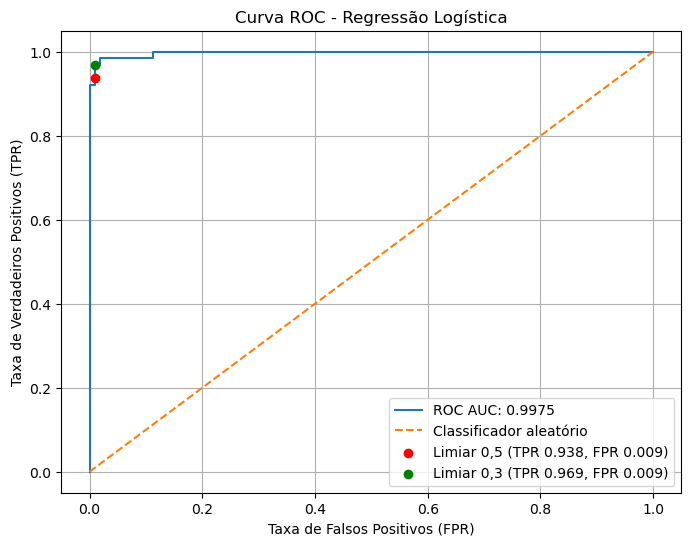

In [210]:
y_prob_lr = modelo_lr.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)
auc_score = roc_auc_score(y_test, y_prob_lr)
print(f"ROC AUC: {auc_score:.4f}")

def ponto_roc(limiar):
    pred = (y_prob_lr >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return fp / (fp + tn), tp / (tp + fn)   # FPR, TPR

fpr_05, tpr_05 = ponto_roc(0.5)
fpr_03, tpr_03 = ponto_roc(0.3)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"ROC AUC: {auc_score:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Classificador aleatório")
plt.scatter(fpr_05, tpr_05, color="red", zorder=5, label=f"Limiar 0,5 (TPR {tpr_05:.3f}, FPR {fpr_05:.3f})")
plt.scatter(fpr_03, tpr_03, color="green", zorder=5, label=f"Limiar 0,3 (TPR {tpr_03:.3f}, FPR {fpr_03:.3f})")
plt.xlabel("Taxa de Falsos Positivos (FPR)")
plt.ylabel("Taxa de Verdadeiros Positivos (TPR)")
plt.title("Curva ROC - Regressão Logística")
plt.legend()
plt.grid(True)
plt.show()

## **CONCLUSÃO DA REGRESSÃO LOGÍSTICA**

**Modelo final:** Regressão Logística (Pipeline com StandardScaler) com limiar de decisão 0,3.

**Desempenho**
- Na validação cruzada com os dados inteiros, a LR foi o melhor dos três modelos: acurácia 0,9737, precisão 0,9863, recall 0,9436, F1 0,9633 e AUC 0,9953.
- No teste (171 pacientes, 64 malignos), o limiar 0,5 perdeu 4 malignos (recall 0,9375). O limiar 0,3 perdeu 2 (recall 0,9688), mantendo 1 falso alarme (precisão 0,9841).

**Escolha do limiar**
- O limiar foi escolhido só com o treino, por validação cruzada. Baixar de 0,5 para 0,3 reduziu os malignos perdidos de 7 para 4, ao custo de 10 falsos alarmes. Abaixo de 0,3 não houve ganho relevante.
- A escolha prioriza o recall, porque deixar passar um tumor maligno é mais grave que um falso alarme. O teste só foi usado depois, uma vez, para confirmar.

**Interpretação**
- Todas as variáveis do top 10 têm odds ratio acima de 1 (valores maiores empurram para maligno), e nenhum intervalo de confiança inclui o 1. O sentido do efeito é seguro, mas a magnitude é imprecisa e os intervalos se sobrepõem.
- O VIF mostrou colinearidade forte nos blocos de tamanho (305 a 3995) e de concavidade (71 a 78). Isso não prejudica a previsão, mas torna instáveis os coeficientes individuais, como o sinal negativo da compacidade_se (VIF 15,2).
- No SHAP, a textura_worst é a variável de maior peso, e o peso da LR está espalhado por muitas variáveis. Por isso a leitura mais segura é por bloco, não por variável isolada.

**Limitações**
- O teste tem poucos malignos (64): uma diferença de 1 ou 2 pacientes muda o recall em 1 a 3 pontos percentuais.
- O limiar 0,3 foi escolhido com poucos casos de erro na validação cruzada (4 a 7 malignos perdidos), então a evidência a favor dele é moderada.

# **RANDOM FOREST CLASSIFIER**

## **TREINANDO O SEGUNDO MODELO**

In [211]:
modelo_rf = RandomForestClassifier(n_estimators=300, 
                                   random_state=42,
                                   )

modelo_rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

## **PREDIÇÃO DO MODELO**

In [212]:
y_pred_rf = modelo_rf.predict(X_test)

## **DESEMPENHO DO MODELO RANDOM FOREST CLASSIFIER**

Acuracia: 0.9766081871345029
Relatorio de Classificacao
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       107
           1       1.00      0.94      0.97        64

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171

Matriz de Confusao
[[107   0]
 [  4  60]]


Text(0.5, 1.0, 'Matriz de Confusao - Random Forest')

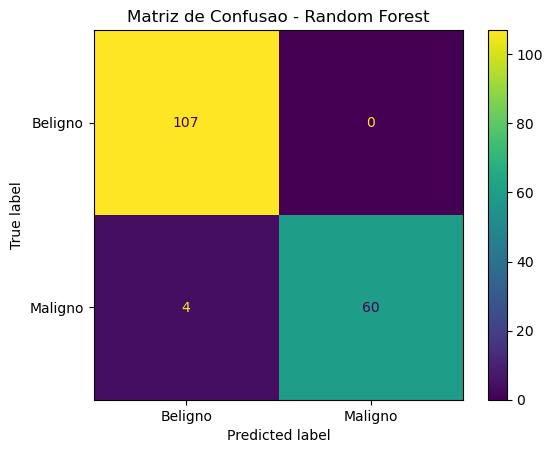

In [213]:
acuracia_rf = accuracy_score(y_test, y_pred_rf)

print(f'Acuracia: {acuracia_rf}')


print('Relatorio de Classificacao')
print(classification_report(y_test, y_pred_rf))



cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Matriz de Confusao")
print(cm_rf)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Beligno', 'Maligno']
)

disp.plot()
plt.title("Matriz de Confusao - Random Forest")

## **IMPORTÂNCIA DAS VARIÁVEIS (FEATURE IMPORTANCES)**

In [214]:
importancias = pd.DataFrame({
    "Variavel": X_train.columns,
    "Importancia": modelo_rf.feature_importances_
})

importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
)

print(importancias.head(10))

                 Variavel  Importancia
22        perimetro_worst     0.141400
23             area_worst     0.139114
7   pontos_concavos_media     0.108203
27  pontos_concavos_worst     0.091209
20             raio_worst     0.086697
0              raio_media     0.054245
3              area_media     0.050832
2         perimetro_media     0.048503
6       concavidade_media     0.039855
26      concavidade_worst     0.033251


### **TOP 10 VARIAVEIS POR IMPORTANCIA - RANDOM FOREST**

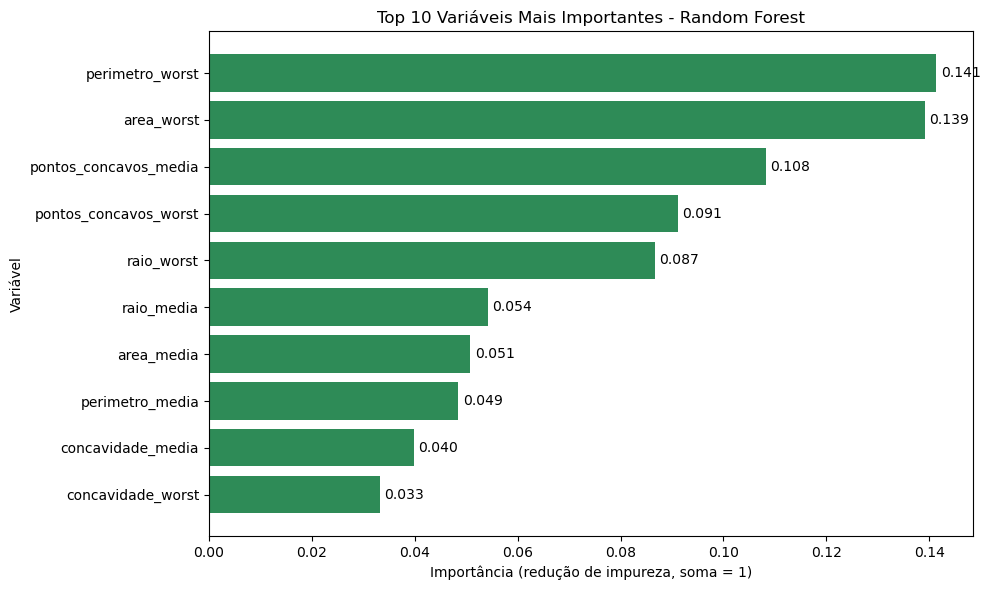

In [215]:
top10_rf = importancias.head(10).sort_values(by="Importancia")

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(top10_rf["Variavel"], top10_rf["Importancia"], color="seagreen")
ax.bar_label(barras, fmt="%.3f", padding=3)
ax.set_xlabel("Importância (redução de impureza, soma = 1)")
ax.set_ylabel("Variável")
ax.set_title("Top 10 Variáveis Mais Importantes - Random Forest")
plt.tight_layout()
plt.show()

## **PERMUTATION IMPORTANCE**

**Uma versão mais confiável: importância por permutação, calculada no teste. Ela embaralha cada variável e vê o quanto o desempenho cai, e é menos enviesada que a do feature_importances_:**

In [216]:
r = permutation_importance(modelo_rf, X_test, y_test, scoring="roc_auc",
                           n_repeats=30, random_state=42)

imp_perm = pd.DataFrame({
    "Variavel": X_test.columns,
    "Importancia": r.importances_mean
}).sort_values("Importancia", ascending=False)

print(imp_perm.head(10))

                 Variavel  Importancia
23             area_worst     0.006673
22        perimetro_worst     0.006457
27  pontos_concavos_worst     0.006318
7   pontos_concavos_media     0.003553
20             raio_worst     0.002470
13                area_se     0.002429
21          textura_worst     0.002200
26      concavidade_worst     0.000964
1           textura_media     0.000589
6       concavidade_media     0.000326


### **TOP 10 VARIAVEIS POR IMPORTANCIA DE PERMUTAÇÃO - RANDOM FOREST**

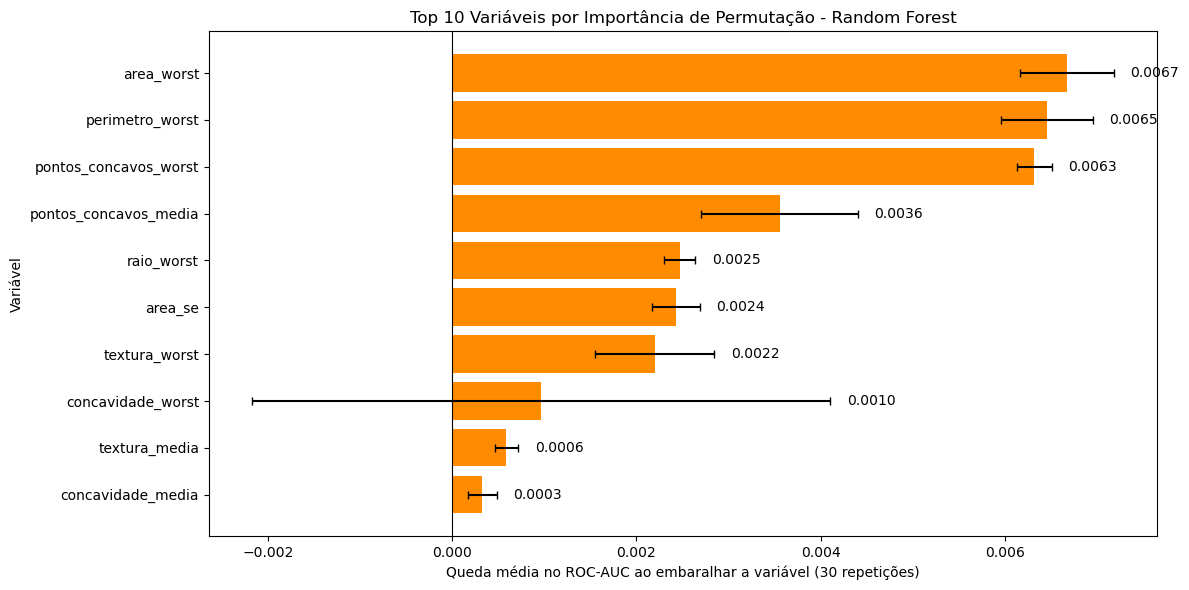

In [217]:
imp_perm["Desvio"] = r.importances_std

top10_perm = imp_perm.head(10).sort_values(by="Importancia")

fig, ax = plt.subplots(figsize=(12, 6))

barras = ax.barh(top10_perm["Variavel"], top10_perm["Importancia"],
                 xerr=top10_perm["Desvio"], color="darkorange", capsize=3)
ax.bar_label(barras, fmt="%.4f", padding=12)
ax.axvline(0, color="black", lw=0.8)

ax.set_xlabel("Queda média no ROC-AUC ao embaralhar a variável (30 repetições)")
ax.set_ylabel("Variável")
ax.set_title("Top 10 Variáveis por Importância de Permutação - Random Forest")
plt.tight_layout()
plt.show()

## **IMPORTANCIA DA PERMUTAÇÃO CONFIAVEL**

In [218]:
imp_perm["Confiavel"] = (imp_perm["Importancia"] - 2 * imp_perm["Desvio"]) > 0
print(imp_perm.head(10))

                 Variavel  Importancia    Desvio  Confiavel
23             area_worst     0.006673  0.000509       True
22        perimetro_worst     0.006457  0.000496       True
27  pontos_concavos_worst     0.006318  0.000192       True
7   pontos_concavos_media     0.003553  0.000851       True
20             raio_worst     0.002470  0.000167       True
13                area_se     0.002429  0.000259       True
21          textura_worst     0.002200  0.000646       True
26      concavidade_worst     0.000964  0.003137      False
1           textura_media     0.000589  0.000126       True
6       concavidade_media     0.000326  0.000157       True


**True significa que a importância fica acima de zero mesmo descontando 2 desvios.**

**Na importância por permutação, área, perímetro e raio no pior caso, além de pontos côncavos, tiveram queda clara no ROC-AUC. 
Variáveis como textura_worst tiveram desvio maior que a média, sendo indistinguíveis de zero.**

## **SHAP DO RANDOM FOREST**

In [219]:
# Explicador para modelos de árvore (o RF não precisa de escalonamento)
# Random Forest do scikit-learn (TreeExplainer): probabilidade. Cada árvore já devolve uma proporção de classe, e o modelo faz a média, então os valores ficam entre -1 e 1. Por isso as barras do RF eram 0,07 e as da LR e do XGB passam de 1.
explainer_rf = shap.TreeExplainer(modelo_rf) 

# Valores SHAP de cada variável para cada paciente do teste
shap_rf = explainer_rf(X_test)

print(shap_rf.values.shape)   # esperado: (171, 30, 2) -> paciente, variável, classe

(171, 30, 2)


In [220]:
# Fica só com a classe 1 (maligno)
shap_rf_maligno = shap_rf[:, :, 1]

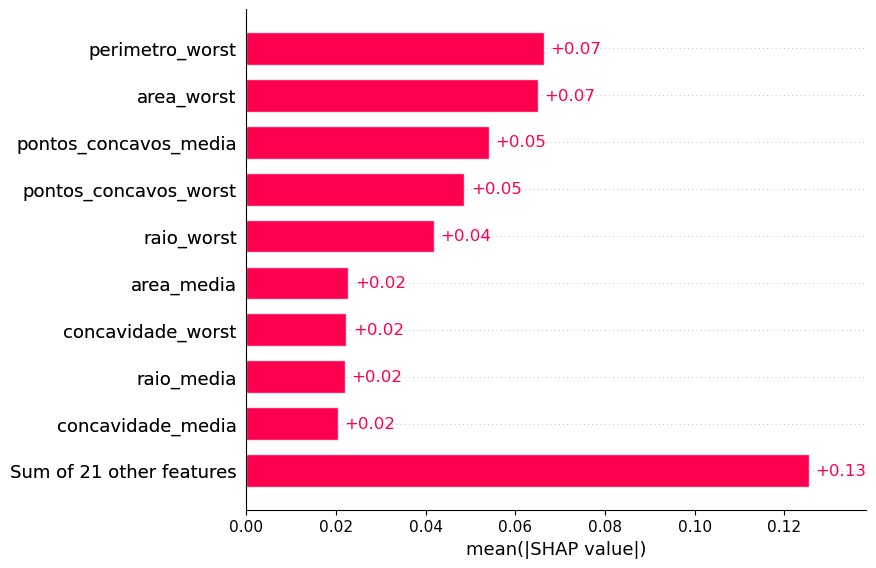

In [221]:
shap.plots.bar(shap_rf_maligno, max_display=10)

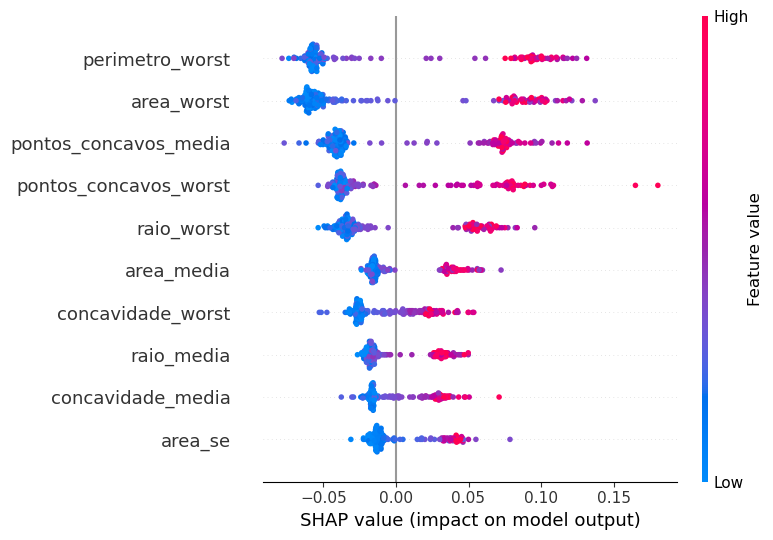

In [222]:
shap.summary_plot(shap_rf_maligno.values, X_test, max_display=10)

#### **OBSERVAÇÕES: SHAP DO RANDOM FOREST**

- As variáveis de maior peso são perimetro_worst e area_worst (0,07 cada), seguidas de pontos_concavos_media, pontos_concavos_worst (0,05) e raio_worst (0,04). Da 6ª posição em diante os valores caem para 0,02 e a ordem é quase empatada.
- O resultado bate com a permutation do RF: o modelo se apoia no bloco de tamanho e nos pontos côncavos.
- Em todas as variáveis do top 10, valores altos (vermelho) empurram para maligno e valores baixos (azul) para benigno. Nenhuma variável tem sinal invertido.
- Diferente da regressão logística, textura e simetria não aparecem entre as principais, e o peso fica mais concentrado em tamanho e concavidade.
- Os valores SHAP do RF estão na escala de probabilidade e os da LR em log-odds, então só a ordem das variáveis é comparável entre os dois modelos.

## **CURVA ROC**

ROC-AUC: 0.9963


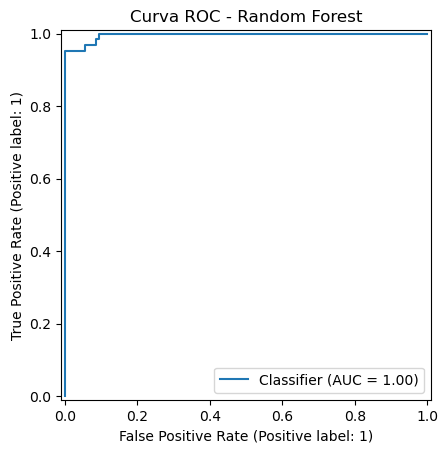

In [223]:
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"ROC-AUC: {roc_auc_rf:.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_rf)
plt.title("Curva ROC - Random Forest")
plt.show()

### **COMPARANDO OS AUC DOS MODELOS LOGISTIC - LOGISTIC REGRESSION e RANDOM FOREST CLASSIFIER**

**Usar predict() no lugar de predict_proba() daria um valor menor e enganoso.**

In [224]:
auc_rf = roc_auc_score(y_test, modelo_rf.predict_proba(X_test)[:,1])
auc_lr = roc_auc_score(y_test, modelo_lr.predict_proba(X_test)[:,1])

print('PONTUAÇÃO DO ROC-AUC RANDOM FOREST')
print(auc_rf)
print('=====================================')
print('PONTUAÇÃO DO ROC-AUC REGRESSÃO LOGISTICA')
print(auc_lr)
print('=====================================')

PONTUAÇÃO DO ROC-AUC RANDOM FOREST
0.9963492990654206
PONTUAÇÃO DO ROC-AUC REGRESSÃO LOGISTICA
0.997517523364486


### **GRAFICO DE COMPARAÇÃO DAS CURVAS ROC - REGRESSÃO LOGISTICA & RANDOM FOREST**

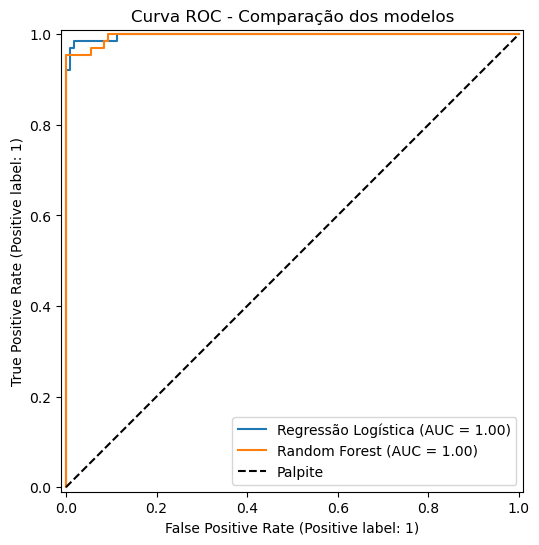

In [225]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_estimator(modelo_lr, X_test, y_test, name="Regressão Logística", ax=ax)
RocCurveDisplay.from_estimator(modelo_rf, X_test, y_test, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Palpite")
ax.legend()
plt.title("Curva ROC - Comparação dos modelos")
plt.show()

**Os dois modelos tiveram ROC-AUC praticamente idênticos (Regressão Logística: 0,998; Random Forest: 0,997), indicando capacidade equivalente de separar tumores benignos e malignos.**

## **TESTE DE McNemar**

**É uma técnica estatística não paramétrica utilizada para comparar duas proporções em amostras pareadas ou dependentes. Ele é amplamente aplicado em estudos antes-e-depois (onde o mesmo grupo é avaliado em dois momentos diferentes) ou em desenhos de caso-controle com pareamento.**

**Como Funciona o Teste**

**A hipótese nula (H₀) pressupõe que as proporções marginais são homogêneas (ou seja, a taxa de mudança de positivo para negativo é igual à de negativo para positivo). 
A fórmula básica do Qui-quadrado de McNemar avalia apenas as células discordantes: 
$$\chi ^{2}=\frac{(B-C)^{2}}{B+C}$$ Nota: Se a soma dos discordantes (B + C) for menor que 25, utiliza-se a versão do teste exato binomial (ou correção de continuidade de Edwards) para garantir a precisão dos resultados**

In [226]:
acerto_lr = np.asarray(y_pred_lr) == np.asarray(y_test)   # True onde a LR acertou
acerto_rf = np.asarray(y_pred_rf) == np.asarray(y_test)   # True onde a RF acertou

ambos_certos  = (acerto_lr & acerto_rf).sum()
so_lr_acertou = (acerto_lr & ~acerto_rf).sum()
so_rf_acertou = (~acerto_lr & acerto_rf).sum()
ambos_errados = (~acerto_lr & ~acerto_rf).sum()

print("Só a LR acertou:", so_lr_acertou)
print("Só a RF acertou:", so_rf_acertou)

tabela = [[ambos_certos, so_lr_acertou],
          [so_rf_acertou, ambos_errados]]

resultado = mcnemar(tabela, exact=True)
print("p-valor:", resultado.pvalue)

Só a LR acertou: 3
Só a RF acertou: 4
p-valor: 1.0


**Teste de Hipotese**

In [227]:
alpha = 0.05
if resultado.pvalue < alpha:
    print("\n[Resultado] Rejeitamos a hipótese nula!")
    print("Há uma diferença estatisticamente significativa entre o Random Forest Classifier e a Regressão Logística.")
else:
    print("\n[Resultado] Não rejeitamos a hipótese nula.")
    print("Não há diferença estatisticamente significativa entre o desempenho dos dois modelos.")


[Resultado] Não rejeitamos a hipótese nula.
Não há diferença estatisticamente significativa entre o desempenho dos dois modelos.


#### **OBSERVAÇÕES: TESTE DE McNEMAR (RANDOM FOREST CONTRA REGRESSÃO LOGÍSTICA)**
- **Embora o modelo Random Forest (RF) tenha obtido 4 acertos na zona de discordância contra 3 acertos do Logistic Regression (LR), o teste de McNemar indicou que não há diferença estatisticamente significativa entre os modelos $p > 0.05$. Portanto, o desempenho de ambos na classificação do câncer de mama é considerado equivalente nesta base de dados, sendo a sutil diferença atribuída ao acaso.**

- Os modelos discordaram em 7 dos 171 pacientes: a regressão logística acertou sozinha em 3 e o Random Forest em 4 (p-valor 1,0).
- Não há evidência de que um modelo erre menos que o outro no teste. Com tão poucas discordâncias o teste tem pouco poder, então o resultado indica que não dá para distinguir os modelos, e não que sejam iguais.
- A regressão logística segue como modelo final pela interpretabilidade e pelo recall com o limiar 0,3, e não por superioridade estatística sobre o Random Forest..**

## **CONCLUSÃO DO RANDOM FOREST**

**Desempenho no teste (limiar 0,5)**
- Acurácia 0,9766, recall 0,9375 (4 malignos perdidos em 64), precisão 1,00 (nenhum falso alarme) e AUC 0,9963.
- Teste de McNemar contra a regressão logística (mesmo limiar de 0,5): os modelos discordaram em 7 pacientes (LR acertou 3 sozinha, RF acertou 4 sozinho, p-valor 1,0). Não dá para distinguir os dois no teste, e o poder do teste é baixo.

**Interpretação**
- Na permutation individual, as maiores quedas de AUC foram de area_worst (0,0063), perimetro_worst (0,0042) e pontos_concavos_worst (0,0041). Cada variável sozinha pesa pouco, porque as outras do bloco cobrem a falta dela.
- Na permutation em grupo, embaralhar o bloco de tamanho derrubou o AUC em 0,0475 e o de concavidade em 0,0312. O RF depende mais do tamanho, ao contrário do XGBoost e da regressão logística, que dependem mais da concavidade.
- No SHAP, perimetro_worst e area_worst lideram (0,07 cada), seguidas de pontos_concavos_media, pontos_concavos_worst (0,05) e raio_worst (0,04). Valores altos empurram para maligno em todas as variáveis do top 10, e textura e simetria não aparecem entre as principais.
- Os três métodos apontam o mesmo conjunto: o bloco de tamanho e os pontos côncavos.

**Limitações**
- O teste tem poucos malignos (64): uma diferença de 1 ou 2 pacientes muda o recall em 1 a 3 pontos percentuais.
- Os hiperparâmetros do RF não foram ajustados (o GridSearch foi feito só no XGBoost).
- O limiar ficou em 0,5. A regressão logística é o modelo final do projeto, com limiar 0,3.
- A comparação do RF com os outros modelos por validação cruzada está na seção de comparação dos três modelos.

# **XGBOOST**
**TREINANDO O TERCEIRO MODELO**

## **INSTALANDO O XGBOOST**

In [228]:
import sys
!{sys.executable} -m pip install xgboost

In [229]:
modelo_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

modelo_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

## **AVALIAÇÃO NO TESTE COM LIMIAR 0,5 (PADRÃO)**

In [230]:
y_pred_xgb = modelo_xgb.predict(X_test)

### **MATRIZ DE CONFUSÃO**

In [231]:
acuracia_xgb = accuracy_score(y_test, y_pred_xgb)

print(f"Acurácia: {acuracia_xgb:.4f}")

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_xgb))

Acurácia: 0.9825

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       107
           1       1.00      0.95      0.98        64

    accuracy                           0.98       171
   macro avg       0.99      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



### **DISPLAY MATRIZ DE CONFUSÃO**

Matriz de Confusão:
[[107   0]
 [  3  61]]


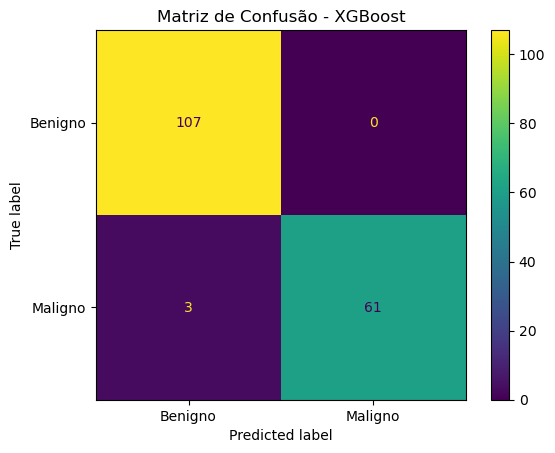

In [232]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print("Matriz de Confusão:")
print(cm_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Benigno", "Maligno"]
)

disp.plot()
plt.title("Matriz de Confusão - XGBoost")
plt.show()

#### **Análise da Matriz de Confusão - XGBOOST (Diagnóstico Benigno vs. Maligno)**

A matriz de confusão obtida no modelo XGBoost (limiar 0,5, teste com stratify=y) apresentou os seguintes resultados:
* **Verdadeiros Benignos (TN):** 107
* **Falsos Benignos (FN):** 3 *(Erro Crítico)*
* **Falsos Malignos (FP):** 0 *(Erro Aceitável)*
* **Verdadeiros Malignos (TP):** 61

##### **Justificativa de Negócio e Impacto Clínico**

Na área da saúde, os erros possuem pesos e consequências completamente diferentes para a vida do paciente. Portanto, a análise do modelo seguiu a seguinte lógica:

1. **O Erro dos 3 Casos (Falsos Negativos):** 
   Este é o cenário mais **crítico e perigoso**. O modelo classificou o tumor como *Benigno*, mas na realidade ele era *Maligno*. Na prática médica, isso significa que o paciente seria enviado para casa sem o tratamento adequado, permitindo a evolução da doença. Nosso objetivo principal deve ser **minimizar esse número ao máximo (idealmente zero)**.

2. **Nenhum Falso Positivo (0 casos):** 
   Neste teste, o modelo não classificou nenhum tumor benigno como *Maligno*. Esse tipo de erro é **aceitável dentro do contexto clínico**: embora gere ansiedade e force o paciente a realizar exames complementares (como novas consultas ou biópsias), **a vida do paciente é preservada**, e o alarme falso é desfeito assim que os novos exames são feitos.

##### **Conclusão**
O modelo atual possui uma excelente **Acurácia (98,3%)**, com **Recall de 95,3%** (61 dos 64 malignos identificados), **Precisão de 100%** e **AUC de 0,9962**. Para torná-lo mais seguro para uso médico, a estratégia correta não é buscar a acurácia perfeita, e sim **reduzir os Falsos Negativos**. Como o modelo não gerou nenhum falso alarme, há espaço para aceitar um aumento controlado nos Falsos Positivos, por exemplo baixando o limiar de decisão, contanto que consigamos capturar mais casos malignos reais.

## **VARIAVEIS MAIS IMPORTANTES DE ACORDO COM O MODELO - XGBOOST**

#### **O que cada tabela mede [DIFERENÇA ENTRE PERMUTATION E FEATURES_IMPORTANCES_]**

* O feature_importances_ mostra quanto cada variável foi usada pelo XGBoost para dividir os dados durante o treino. Descreve como o modelo foi construído.

* A permutation mostra quanto o AUC no teste cai quando a variável é embaralhada. Descreve o que o modelo perde de verdade sem ela.

#### **O feature_importances_ mostra quanto o modelo usou cada variável para decidir entre benigno e maligno**

In [233]:
importancias_xgb = pd.DataFrame({
    "Variavel": X_train.columns,
    "Importancia": modelo_xgb.feature_importances_
})

importancias_xgb = importancias_xgb.sort_values(
    by="Importancia",
    ascending=False
)

print(importancias_xgb.head(10))

                 Variavel  Importancia
22        perimetro_worst     0.229077
20             raio_worst     0.190556
7   pontos_concavos_media     0.185710
3              area_media     0.076811
27  pontos_concavos_worst     0.045440
26      concavidade_worst     0.031175
28         simetria_worst     0.026343
1           textura_media     0.018492
0              raio_media     0.018190
14           suavidade_se     0.017801


## **PERMUTATION IMPORTANCE**

### **PERMUTAÇÃO $INDIVIDUAL$ DO 3 MODELOS**

 **A lista da PERMUTAÇÃO mostra as variáveis cuja falta o modelo mais sentiria, da maior queda de AUC para a menor.**

In [234]:
modelos = {"XGB": modelo_xgb, "LOGISTIC REGRESSION": modelo_lr, "RANDOM FOREST CLASSIFIER": modelo_rf}  # ajuste para os nomes que você usou
perm = {}

for nome, m in modelos.items():
    r = permutation_importance(m, X_test, y_test, scoring="roc_auc",
                               n_repeats=30, random_state=42)
    perm[nome] = pd.DataFrame({
        "Variavel": X_test.columns,
        "Importancia": r.importances_mean,
        "Desvio": r.importances_std
    }).sort_values("Importancia", ascending=False)
    print(nome)
    print(perm[nome].head(10), "\n")

XGB
                 Variavel  Importancia    Desvio
26      concavidade_worst     0.006148  0.003032
27  pontos_concavos_worst     0.003962  0.002777
13                area_se     0.003631  0.002841
21          textura_worst     0.003578  0.002169
22        perimetro_worst     0.002750  0.002456
7   pontos_concavos_media     0.001752  0.002600
23             area_worst     0.001339  0.001277
20             raio_worst     0.001202  0.001350
24        suavidade_worst     0.001076  0.000861
16         concavidade_se     0.000492  0.000133 

LOGISTIC REGRESSION
                 Variavel  Importancia    Desvio
28         simetria_worst     0.008367  0.001900
21          textura_worst     0.007847  0.003140
26      concavidade_worst     0.005335  0.002031
6       concavidade_media     0.002838  0.001523
10                raio_se     0.002828  0.002297
13                area_se     0.002463  0.002195
27  pontos_concavos_worst     0.002385  0.001241
7   pontos_concavos_media     0.002195  0.0

#### **OBSERVAÇÕES: PERMUTATION INDIVIDUAL DOS TRÊS MODELOS**

- Sete variáveis aparecem no top 10 dos três modelos (XGBoost, Regressão Logística e Random Forest): concavidade_worst, pontos_concavos_worst, pontos_concavos_media, area_worst, raio_worst, area_se e textura_worst. As medidas de tamanho e concavidade do tumor são as que mais sustentam a previsão, junto com a textura_worst.
- A ordem das variáveis muda entre os modelos e quase todas as diferenças estão dentro do desvio, então não dá para apontar uma única variável campeã. A concavidade_worst lidera no XGBoost (0,0061), mas a vantagem sobre a segunda (0,0040) é menor que o desvio dela (0,0030). Na regressão logística ela fica em 3º (0,0053) e no Random Forest cai para 8º (0,0010).
- As importâncias individuais são pequenas (no máximo 0,0084) porque o AUC base já é próximo de 1 e as variáveis são muito correlacionadas: quando uma é embaralhada, as outras cobrem a falta. Por isso a leitura mais segura é por bloco, não por variável.
- A Regressão Logística distribui o peso por mais tipos de medida: as duas primeiras são simetria_worst (0,0084) e textura_worst (0,0078), e também aparece raio_se. O Random Forest se concentra em tamanho e pontos côncavos (area_worst, perimetro_worst e pontos_concavos_worst, as três entre 0,0063 e 0,0067).

## **PERMUTATION EM $GRUPO$ DOS TRÊS MODELOS**

**EMBARALHAMENTO POR GRUPO**

In [235]:
def perm_grupo(modelo, X, y, cols, n_repeats=30, seed=42):
    rng = np.random.RandomState(seed)
    auc_base = roc_auc_score(y, modelo.predict_proba(X)[:, 1])
    quedas = []
    for _ in range(n_repeats):
        Xp = X.copy()
        idx = rng.permutation(len(Xp))
        # embaralha o grupo inteiro com o mesmo índice, mantendo a relação entre elas
        Xp[cols] = Xp[cols].iloc[idx].values
        auc_perm = roc_auc_score(y, modelo.predict_proba(Xp)[:, 1])
        quedas.append(auc_base - auc_perm)
    return np.mean(quedas), np.std(quedas)

grupos = {
    "tamanho_worst": ["area_worst", "raio_worst", "perimetro_worst"],
    "concavidade": ["concavidade_worst", "pontos_concavos_worst", "pontos_concavos_media"],
}

for nome, m in modelos.items():
    for grupo, cols in grupos.items():
        media, desvio = perm_grupo(m, X_test, y_test, cols)
        print(f"{nome} | {grupo}: queda média do AUC = {media:.4f} (desvio {desvio:.4f})")

XGB | tamanho_worst: queda média do AUC = 0.0334 (desvio 0.0074)
XGB | concavidade: queda média do AUC = 0.0519 (desvio 0.0087)
LOGISTIC REGRESSION | tamanho_worst: queda média do AUC = 0.0258 (desvio 0.0048)
LOGISTIC REGRESSION | concavidade: queda média do AUC = 0.0363 (desvio 0.0067)
RANDOM FOREST CLASSIFIER | tamanho_worst: queda média do AUC = 0.0631 (desvio 0.0113)
RANDOM FOREST CLASSIFIER | concavidade: queda média do AUC = 0.0359 (desvio 0.0060)


#### **OBSERVAÇÕES: PERMUTATION EM GRUPO DOS TRÊS MODELOS**

- A Permutation individual subestimava o peso dessas informações por causa da colinearidade. Individualmente, cada variável derrubava o AUC em 0,001 a 0,008, mas embaralhar o bloco inteiro derrubou de 0,0258 a 0,0631, de 3 a 6 vezes a soma das individuais. O que importa é o bloco.
- O XGBoost e a regressão logística dependem mais do bloco de concavidade (0,0519 contra 0,0334 no XGBoost, 0,0363 contra 0,0258 na regressão logística), com razão de cerca de 1,5 e 1,4 vez. No XGBoost a diferença é maior que os desvios, e na regressão logística é um sinal moderado.
- O Random Forest depende mais do bloco de tamanho (0,0631 contra 0,0359, cerca de 1,8 vez), com diferença maior que os desvios.
- Os três modelos usam os dois blocos, mas cada um se apoia mais em um deles. A conclusão segura é que o modelo depende fortemente de dois tipos de informação, o tamanho do tumor e a concavidade do contorno, e não de uma variável ou de um bloco específico.

#### **RETREINANDO COM AS VARIÁVEIS DO TOPO**

In [236]:
top_vars = perm["XGB"]["Variavel"].head(6).tolist()
top_sem_conc = [v for v in top_vars if v != "concavidade_worst"]

def auc_teste(cols):
    m = clone(modelo_xgb)
    m.fit(X_train[cols], y_train)
    return roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])

print("Todas as variáveis:       ", round(auc_teste(X_train.columns.tolist()), 4))
print("Só as top 6:              ", round(auc_teste(top_vars), 4))
print("Top 6 sem concavidade_worst:", round(auc_teste(top_sem_conc), 4))

Todas as variáveis:        0.9962
Só as top 6:               0.995
Top 6 sem concavidade_worst: 0.9943


**AQUI SERVE PARA VER COMO O MODELO REAGE APÓS PERDER A PRINCIPAL VARIÁVEL DE PREVISÃO**

In [237]:
m_sem = clone(modelo_xgb)
m_sem.fit(X_train[top_sem_conc], y_train)

pd.DataFrame({
    "Variavel": top_sem_conc,
    "Importancia": m_sem.feature_importances_
}).sort_values("Importancia", ascending=False)

,Variavel,Importancia
3,perimetro_worst,0.555159
4,pontos_concavos_media,0.260775
0,pontos_concavos_worst,0.087390
2,textura_worst,0.058276
1,area_se,0.038400


**Comparação com e sem concavidade_worst**

In [238]:
m_top6 = clone(modelo_xgb)
m_top6.fit(X_train[top_vars], y_train)

tabela = pd.DataFrame({
    "Variavel": top_vars,
    "Com_concavidade_worst": m_top6.feature_importances_
}).merge(
    pd.DataFrame({
        "Variavel": top_sem_conc,
        "Sem_concavidade_worst": m_sem.feature_importances_
    }),
    on="Variavel", how="left"
)
print(tabela.sort_values("Com_concavidade_worst", ascending=False))

                Variavel  Com_concavidade_worst  Sem_concavidade_worst
4        perimetro_worst               0.589521               0.555159
5  pontos_concavos_media               0.161768               0.260775
1  pontos_concavos_worst               0.102498               0.087390
0      concavidade_worst               0.056010                    NaN
3          textura_worst               0.052296               0.058276
2                area_se               0.037907               0.038400


**AGORA COMO O MODELO REAGE SEM O BLOCO INTEIRO DAS CONCAVIDADES**

In [239]:
sem_bloco_conc = [v for v in top_vars if v not in grupos["concavidade"]]
print("Top 6 sem o bloco de concavidade:", round(auc_teste(sem_bloco_conc), 4))

Top 6 sem o bloco de concavidade: 0.9806


#### **OBSERVAÇÕES: RETREINANDO COM AS VARIÁVEIS DO TOPO**

- O primeiro teste (permutation em grupo) mede o quanto o modelo já treinado depende do bloco. O segundo (retreino) mede se o bloco é indispensável para prever bem. O modelo treinado depende muito do bloco de concavidade (queda de 0,0519 no AUC), mas os dados não precisam dele para chegar a um AUC alto.
- As top 6 mantêm quase toda a capacidade do modelo: AUC de 0,9950 contra 0,9962 com todas as variáveis.
- Tirar só a concavidade_worst não piorou o modelo (0,9943 contra 0,9950). As outras variáveis do bloco, principalmente pontos_concavos_media, cobrem a falta dela.
- Tirar o bloco inteiro de concavidade derruba o AUC de 0,9950 para 0,9806. O bloco contribui, mas o modelo ainda chega a um AUC alto com perimetro_worst, area_se e textura_worst.
- As diferenças menores que 0,002 estão dentro do ruído de um teste com 171 pacientes. A de 0,0144 é a maior, mas a validação cruzada por bloco, refeita com a divisão atual, é que confirma se ela se mantém.

## **SHAP DO XGBOOST**

In [240]:
import shap

# Explicador para modelos de árvore (o XGBoost não precisa de escalonamento)
explainer_xgb = shap.TreeExplainer(modelo_xgb) # XGBoost (TreeExplainer) usa log-odds. Ele explica a saída bruta do modelo, antes de virar probabilidade.

# Valor SHAP de cada variável para cada paciente do teste
shap_xgb = explainer_xgb(X_test)

print(shap_xgb.values.shape)   # esperado: (171, 30)

(171, 30)


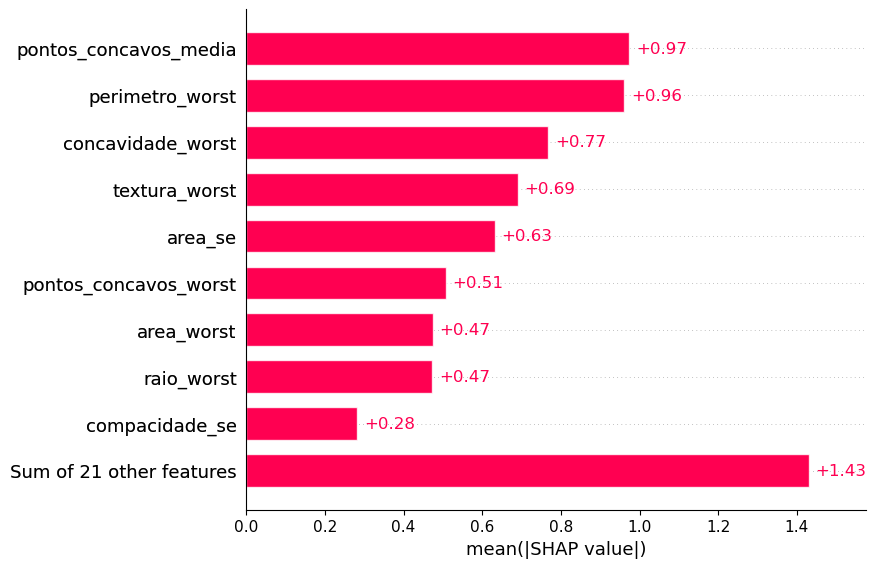

In [241]:
shap.plots.bar(shap_xgb, max_display=10)

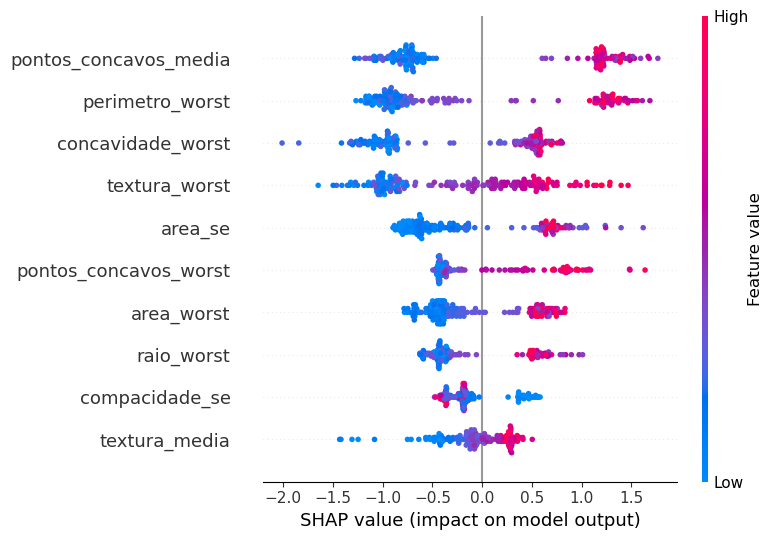

In [242]:
shap.summary_plot(shap_xgb.values, X_test, max_display=10)

#### **OBSERVAÇÕES: SHAP DO XGBOOST**

- As variáveis que mais deslocam as previsões são pontos_concavos_media (0,97) e perimetro_worst (0,96), quase empatadas, seguidas de concavidade_worst (0,77), textura_worst (0,69) e area_se (0,63). O topo mistura o bloco de concavidade, o bloco de tamanho e a textura.
- Em quase todas as variáveis do top 10, valores altos (vermelho) empurram a previsão para maligno e valores baixos (azul) para benigno. A compacidade_se tem peso pequeno (0,28) e direção pouco clara.
- O peso do XGBoost está mais concentrado que o da regressão logística: as 21 variáveis restantes somam 1,43, contra 6,05 na LR. As duas estão em log-odds, então o tamanho das barras é comparável.
- A ordem difere da permutation e do feature_importances_ porque cada método mede uma coisa. O SHAP e o feature_importances_ medem o quanto o modelo usa a variável, e a permutation mede o quanto ele sentiria falta dela. A pontos_concavos_media lidera o SHAP (0,97), mas é a 6ª na permutation (0,0018), porque as outras variáveis de concavidade cobrem a falta dela. A concavidade_worst é a 1ª na permutation e a 3ª no SHAP, porque traz informação que as outras não substituem.
- O que se repete nos três métodos é o conjunto: tamanho e concavidade sustentam o modelo. A posição de cada variável muda com o método, e por isso a leitura mais segura é por bloco.
- A textura_worst tem peso relevante no XGBoost e na regressão logística, mas não aparece entre as principais do SHAP do Random Forest.

# **XGBOOST OTIMIZADO (GRIDSEARCH PRIORIZANDO RECALL)**

**Validação cruzada estratificada de 5 folds - COMPARAÇÃO DOS TRÊS MODELOS COM VÁRIAS MÉTRICAS**

In [243]:
cv_simples = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

def tabela_metricas(modelos_dict):
    linhas = []
    for nome, m in modelos_dict.items():
        r = cross_validate(m, X, y, cv=cv_simples, scoring=scoring)
        linha = {"Modelo": nome}
        for metrica in scoring:
            v = r[f"test_{metrica}"]
            linha[metrica.upper()] = f"{v.mean():.4f} (± {v.std():.4f})"
        linhas.append(linha)
    return pd.DataFrame(linhas)

modelos_comparacao = {
    "LR": modelo_lr,
    "RF": modelo_rf,
    "XGB": modelo_xgb,
}

tabela = tabela_metricas(modelos_comparacao)
tabela

,Modelo,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
0,LR,0.9737 (± 0.0166),0.9863 (± 0.0182),0.9436 (± 0.0525),0.9633 (± 0.0240),0.9953 (± 0.0053)
1,RF,0.9526 (± 0.0131),0.9461 (± 0.0389),0.9295 (± 0.0572),0.9355 (± 0.0194),0.9895 (± 0.0077)
2,XGB,0.9613 (± 0.0142),0.9588 (± 0.0326),0.9389 (± 0.0480),0.9473 (± 0.0202),0.9936 (± 0.0043)


#### **OBSERVAÇÕES: COMPARAÇÃO DOS TRÊS MODELOS COM VÁRIAS MÉTRICAS**

Validação cruzada estratificada de 5 folds com os 569 pacientes (X e y inteiros). Em cada fold o modelo é treinado de novo em 4 partes e avaliado na parte restante.

- A regressão logística tem as maiores médias em todas as métricas: acurácia 0,9737, precisão 0,9863, recall 0,9436, F1 0,9633 e AUC 0,9953. O XGBoost vem em seguida (acurácia 0,9613, AUC 0,9936) e o Random Forest por último (acurácia 0,9526, AUC 0,9895).
- As diferenças de AUC (0,002 a 0,006) são menores que os desvios (0,004 a 0,008), então os três modelos empatam na capacidade de ordenar malignos e benignos. Na acurácia, a vantagem da regressão logística sobre o Random Forest (0,021) é de cerca de 1,5 desvio, um sinal moderado.
- O recall, a métrica mais importante para tumor maligno, fica entre 0,93 e 0,94 nos três modelos, com desvios de 0,048 a 0,057, dez vezes maiores que as diferenças entre eles. Os três perdem cerca de 6% dos malignos com o limiar 0,5, e nenhum se destaca.
- A regressão logística tem a maior precisão (0,9863): quando aponta maligno, quase sempre acerta.
- O recall varia bastante entre folds (± 0,05) porque cada fold tem poucos malignos, e um ou dois erros mudam o valor.
- Esses números diferem dos do teste porque a validação cruzada usa os dados inteiros e a média de 5 avaliações, enquanto o teste é uma única avaliação em 171 pacientes. A média da validação cruzada é a estimativa mais estável.
- Conclusão: a regressão logística lidera ou empata em tudo e é a mais interpretável, e o recall é o ponto a melhorar, o que foi tratado ajustando o limiar.

**AJUSTE DE HIPERPARÂMETROS DO XGBOOST (GRIDSEARCH PRIORIZANDO RECALL)**

In [244]:
xgb_base = XGBClassifier(random_state=42, eval_metric="logloss")

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="recall",
    cv=cv_simples,
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X, y)

print("Melhores parâmetros:", grid_search.best_params_)
print(f"Melhor recall encontrado: {grid_search.best_score_:.4f}")

modelo_xgb_otimizado = grid_search.best_estimator_

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Melhores parâmetros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.8}
Melhor recall encontrado: 0.9576


#### **OBSERVAÇÕES: AJUSTE DE HIPERPARÂMETROS DO XGBOOST (GRIDSEARCH PRIORIZANDO RECALL)**

O GridSearch testou 108 combinações de hiperparâmetros (n_estimators, max_depth, learning_rate, subsample e colsample_bytree) com validação cruzada estratificada de 5 folds nos 569 pacientes (540 treinos), escolhendo a combinação de maior recall, porque deixar passar um tumor maligno é o erro mais grave.

- Melhores parâmetros: colsample_bytree 0,8, learning_rate 0,1, max_depth 4, n_estimators 300 e subsample 0,8. O melhor recall do GridSearch foi 0,9576.
- Comparando o XGBoost otimizado com o padrão, na mesma validação cruzada: recall 0,9528 contra 0,9389, acurácia 0,9666 contra 0,9613 e F1 0,9547 contra 0,9473. A precisão (0,9583 contra 0,9588) e o AUC (0,9936 nos dois) não mudaram.
- O ganho de recall (0,0139) é cerca de um terço do desvio (± 0,042), então não dá para afirmar que o ajuste ajudou. A direção é a esperada, sem perder precisão, mas está dentro do ruído.
- Os parâmetros escolhidos estão no limite da grade (max_depth 4, learning_rate 0,1 e n_estimators 300 são os maiores valores testados), então uma grade maior poderia achar algo ligeiramente melhor.
- Os parâmetros foram escolhidos nos mesmos dados e nos mesmos folds em que o modelo foi avaliado, então o resultado do otimizado é um pouco otimista, e a vantagem real sobre o padrão deve ser ainda menor.
- O recall de 0,9576 do GridSearch difere do 0,9528 da avaliação, embora o modelo, os dados e os folds sejam os mesmos. A diferença (0,005) é pequena e pode vir de variação do XGBoost entre execuções.
- ##### **Conclusão**
- o ajuste não mudou o modelo de forma relevante, e o recall do XGBoost continua entre 0,94 e 0,95. O ajuste que mais afeta o recall é o limiar de decisão, e não os hiperparâmetros.

In [245]:
# Se você já rodou o GridSearch e tem o modelo_xgb_otimizado, rode só a avaliação:
modelos_otimizado = {"XGB otimizado": modelo_xgb_otimizado}
tabela_metricas(modelos_otimizado)

,Modelo,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
0,XGB otimizado,0.9666 (± 0.0151),0.9583 (± 0.0246),0.9528 (± 0.0421),0.9547 (± 0.0209),0.9936 (± 0.0063)


## **CURVA ROC**

ROC-AUC: 0.9962


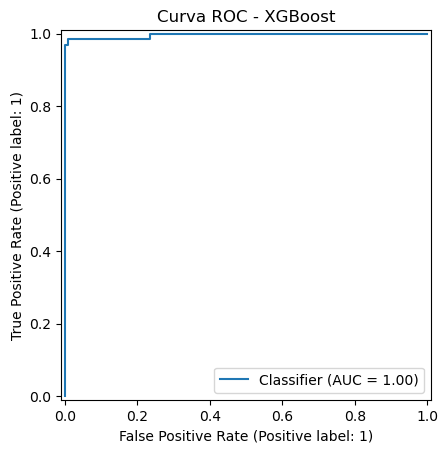

In [246]:
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print(f"ROC-AUC: {roc_auc_xgb:.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_xgb)
plt.title("Curva ROC - XGBoost")
plt.show()

In [247]:
print(roc_auc_score(y_test, y_prob_rf))
print(roc_auc_score(y_test, y_prob_xgb))

0.9963492990654206
0.9962032710280374


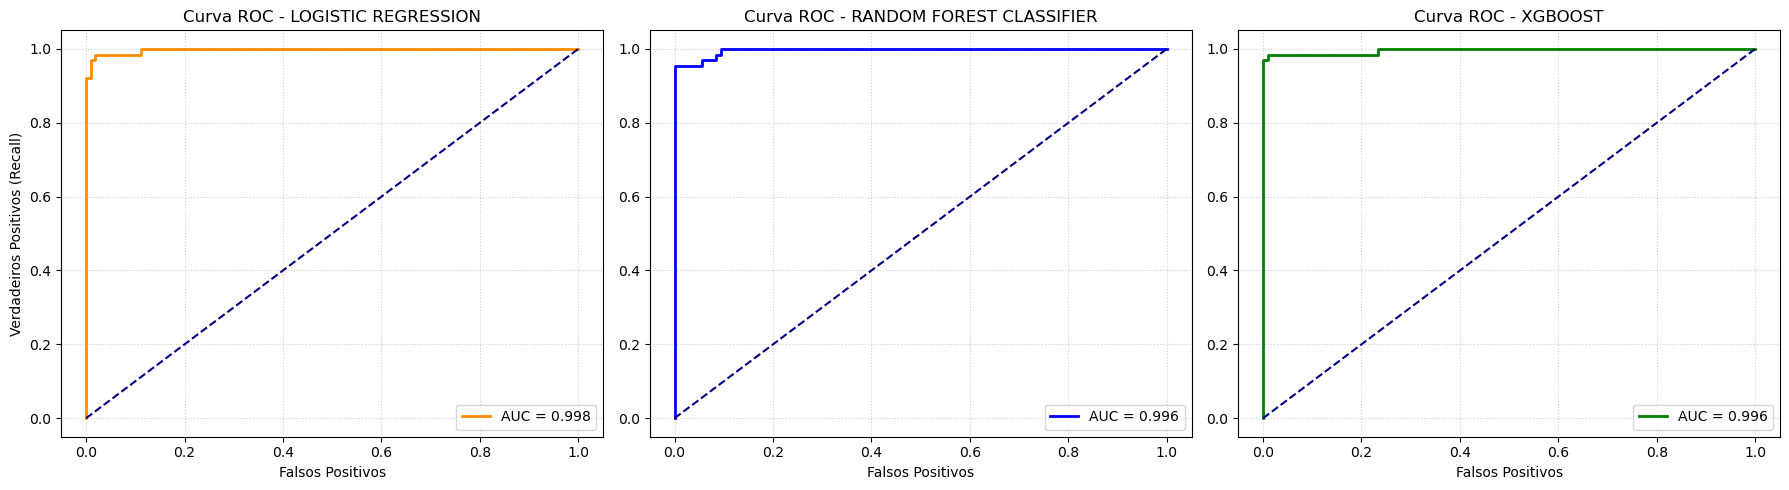

In [248]:
# 1. Pegar as probabilidades da classe positiva (Maligno) para cada modelo
y_prob_lr = modelo_lr.predict_proba(X_test)[:, 1]
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

# 2. Calcular as curvas ROC e AUC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = auc(fpr_lr, tpr_lr)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = auc(fpr_rf, tpr_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
auc_xgb = auc(fpr_xgb, tpr_xgb)

# 3. Criar a estrutura com 3 subgráficos lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Gráfico 1: Logistic Regression ---
axes[0].plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label=f'AUC = {auc_lr:.3f}')
axes[0].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[0].set_title('Curva ROC - LOGISTIC REGRESSION')
axes[0].set_xlabel('Falsos Positivos')
axes[0].set_ylabel('Verdadeiros Positivos (Recall)')
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Gráfico 2: Random Forest Classifier ---
axes[1].plot(fpr_rf, tpr_rf, color='blue', lw=2, label=f'AUC = {auc_rf:.3f}')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_title('Curva ROC - RANDOM FOREST CLASSIFIER')
axes[1].set_xlabel('Falsos Positivos')
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle=':', alpha=0.6)

# --- Gráfico 3: XGBOOST ---
axes[2].plot(fpr_xgb, tpr_xgb, color='green', lw=2, label=f'AUC = {auc_xgb:.3f}')
axes[2].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[2].set_title('Curva ROC - XGBOOST')
axes[2].set_xlabel('Falsos Positivos')
axes[2].legend(loc="lower right")
axes[2].grid(True, linestyle=':', alpha=0.6)

# Ajusta o espaçamento para não cortar os textos
plt.tight_layout()
plt.show()

In [249]:
score_auc_lr = roc_auc_score(y_test, y_prob_lr)
score_auc_rf = roc_auc_score(y_test, y_prob_rf)
score_auc_xgb = roc_auc_score(y_test, y_prob_xgb)


print('SCORE AUC - LOGISTIC REGRESSION')
print(score_auc_lr)
print('=====================================')
print('SCORE AUC - RANDOM FOREST CLASSIFIER')
print(score_auc_rf)
print('=====================================')
print('SCORE AUC - XGBOOST')
print(score_auc_xgb)

SCORE AUC - LOGISTIC REGRESSION
0.997517523364486
SCORE AUC - RANDOM FOREST CLASSIFIER
0.9963492990654206
SCORE AUC - XGBOOST
0.9962032710280374


# **VALIDAÇÃO CRUZADA**

## **VALIDAÇÃO CRUZADA DOS $CENÁRIOS$ NOS TRÊS MODELOS**

In [250]:
cv_5x5 = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

resultados = []

for nome, m in modelos.items():
    top = perm[nome]["Variavel"].head(6).tolist()   # top 6 de cada modelo
    cenarios = {
        "Todas as variáveis": X_train.columns.tolist(),
        "Top 6": top,
        "Top 6 sem concavidade_worst": [v for v in top if v != "concavidade_worst"],
        "Top 6 sem o bloco de concavidade": [v for v in top if v not in grupos["concavidade"]],
    }
    for cenario, cols in cenarios.items():
        scores = cross_val_score(clone(m), X_train[cols], y_train, scoring="roc_auc", cv=cv_5x5)  
        resultados.append({"Modelo": nome, "Cenario": cenario,
                           "AUC_medio": scores.mean(), "Desvio": scores.std()})


resultados_df = pd.DataFrame(resultados).round(4)
resultados_df

,Modelo,Cenario,AUC_medio,Desvio
0,XGB,Todas as variáveis,0.9883,0.0094
1,XGB,Top 6,0.9881,0.0089
2,XGB,Top 6 sem concavidade_worst,0.9872,0.0094
3,XGB,Top 6 sem o bloco de concavidade,0.9791,0.0123
4,LOGISTIC REGRESSION,Todas as variáveis,0.9925,0.0080
5,LOGISTIC REGRESSION,Top 6,0.9807,0.0104
6,LOGISTIC REGRESSION,Top 6 sem concavidade_worst,0.9806,0.0091
7,LOGISTIC REGRESSION,Top 6 sem o bloco de concavidade,0.9806,0.0091
8,RANDOM FOREST CLASSIFIER,Todas as variáveis,0.9859,0.0098
9,RANDOM FOREST CLASSIFIER,Top 6,0.9789,0.0143


## **VALIDAÇÃO CRUZADA POR $BLOCO$ NOS TRÊS MODELOS**

In [251]:
bloco_tamanho = ["area_worst", "raio_worst", "perimetro_worst"]
bloco_conc = ["concavidade_worst", "pontos_concavos_worst", "pontos_concavos_media"]

cenarios_bloco = {
    "Todas as variáveis": X_train.columns.tolist(),
    "Tamanho + concavidade": bloco_tamanho + bloco_conc,
    "Só tamanho": bloco_tamanho,
    "Só concavidade": bloco_conc,
}

resultados_bloco = []
for nome, m in modelos.items():
    for cenario, cols in cenarios_bloco.items():
        scores = cross_val_score(clone(m), X_train[cols], y_train,
                                 scoring="roc_auc", cv=cv_5x5)
        resultados_bloco.append({"Modelo": nome, "Cenario": cenario,
                                 "AUC_medio": scores.mean(), "Desvio": scores.std()})

resultados_bloco = pd.DataFrame(resultados_bloco).round(4)
resultados_bloco

,Modelo,Cenario,AUC_medio,Desvio
0,XGB,Todas as variáveis,0.9883,0.0094
1,XGB,Tamanho + concavidade,0.9725,0.0175
2,XGB,Só tamanho,0.9478,0.0325
3,XGB,Só concavidade,0.9551,0.0251
4,LOGISTIC REGRESSION,Todas as variáveis,0.9925,0.0080
5,LOGISTIC REGRESSION,Tamanho + concavidade,0.9835,0.0109
6,LOGISTIC REGRESSION,Só tamanho,0.9713,0.0173
7,LOGISTIC REGRESSION,Só concavidade,0.9618,0.0221
8,RANDOM FOREST CLASSIFIER,Todas as variáveis,0.9859,0.0098
9,RANDOM FOREST CLASSIFIER,Tamanho + concavidade,0.9761,0.0197


**OBSERVAÇÃO DA VALIDAÇÃO CRUZADA POR $BLOCO$ NOS TRÊS MODELO:**

**Tamanho e concavidade do tumor se complementam, e a informação está espalhada pelos dois blocos em vez de concentrada em uma variável ou em um bloco só.**

#### **COLINEARIDADE DAS VARIÁVEIS DE TAMANHO**

**Colinearidade é quando duas ou mais variáveis do Conjunto carregam praticamente a mesma informação, ou seja, uma pode ser quase prevista a partir da outra. Isso aparece como correlação muito alta entre elas.**

In [252]:
cols_tamanho = ['area_worst', 'raio_worst', 'perimetro_worst']
print(X_train[cols_tamanho].corr().round(3))

                 area_worst  raio_worst  perimetro_worst
area_worst            1.000       0.985            0.978
raio_worst            0.985       1.000            0.993
perimetro_worst       0.978       0.993            1.000


#### **COLINEARIDADE DAS VARIÁVEIS DE CONCAVIDADE**

In [253]:
colunas = df.columns[df.columns.str.contains('conca', case=False)]

print(colunas.tolist())

['concavidade_media', 'pontos_concavos_media', 'concavidade_se', 'pontos_concavos_se', 'concavidade_worst', 'pontos_concavos_worst']


In [254]:
cols_concavidade = ['concavidade_media', 'concavidade_se', 'concavidade_worst']

print(X_train[cols_concavidade].corr().round(3))

                   concavidade_media  concavidade_se  concavidade_worst
concavidade_media              1.000           0.678              0.879
concavidade_se                 0.678           1.000              0.652
concavidade_worst              0.879           0.652              1.000


#### **OBSERVAÇÃO DA VALIDAÇÃO DOS TRÊS MODELOS**

**Validação cruzada estratificada 5x5 (25 AUCs por cenário) no conjunto de treino, para XGBoost, Regressão Logística e Random Forest.**

- VALIDAÇÃO CRUZADA DOS CENÁRIOS NOS TRÊS MODELOS: Com todas as variáveis, os três modelos ficam muito próximos: LR (0,9926), XGB (0,9887) e RF (0,9833). As diferenças de AUC entre as médias são mínimas (0,0039 a 0,0093), sobrepondo-se aos desvios padrão (que variam de 0,0060 a 0,0075). Portanto, estatisticamente, nenhum modelo é claramente superior neste cenário. A LR entrega a maior média, mas o XGB possui o menor desvio padrão absoluto (0,0060).
- Nos cenários por bloco: Juntar "tamanho + concavidade" ganha cerca de 0,01 a 0,03 de AUC sobre o bloco de "só tamanho" nos três algoritmos (ganho de 0,0374 no XGB, 0,0115 na LR e 0,0280 na RF). Quando comparado ao bloco de "só concavidade", a união dos blocos gera um ganho que varia de 0,0115 a 0,0205.
- Comparação entre blocos isolados: O bloco de "só concavidade" supera o de "só tamanho" no XGBoost (diferença de 0,0169) e na Random Forest (diferença de 0,0115). No entanto, na Regressão Logística, o comportamento se inverte e "só tamanho" performa melhor por uma margem sutil (0,0078). Em quase todos os casos, essas diferenças são próximas ou menores que os desvios padrão dos próprios cenários (que chegam a 0,0339), mostrando que os blocos isolados flutuam de forma parecida.
- Impacto das demais variáveis: O restante das variáveis ainda acrescenta valor ao modelo: ao passar de "tamanho + concavidade" para o cenário com "todas as variáveis", o AUC médio sobe entre 0,0086 e 0,0168.
- Consistência da Regressão Logística: A Regressão Logística entrega as melhores médias de AUC em todos os cenários analisados e mantém desvios muito baixos. Por se tratar de um modelo linear altamente interpretável, ela se mostra a escolha mais robusta e eficiente para o problema, resolvendo-o tão bem quanto (ou melhor que) os modelos baseados em árvores.
- Padrões robustos: As diferenças de AUC entre cenários concorrentes são, em sua maioria, de magnitude similar aos desvios padrão. O que dá segurança estatística à análise é o padrão de ganho de performance se repetir de forma consistente e previsível na estrutura dos três modelos.
Conclusão: O desempenho preditivo é sustentado pelo conjunto combinado das medidas de tamanho e concavidade do tumor. Nenhuma variável ou bloco isolado é insubstituível, e os dois conceitos se complementam para atingir o topo de performance das métricas.

**Conclusão: O desempenho preditivo é sustentado pelo conjunto combinado das medidas de tamanho e concavidade do tumor. Nenhuma variável ou bloco isolado é insubstituível, e os dois conceitos se complementam para atingir o topo de performance das métricas.**

# **TESTE DE McNEMAR: XGBOOST CONTRA REGRESSÃO LOGÍSTICA**

**TESTE DE McNEMAR COM TESTE DE HIPOTESE**

In [255]:
# Verificação de segurança do tamanho da base
assert len(y_test) == 171, f"A base de teste precisa ter 171 elementos. O seu tem {len(y_test)}."

# 2. Calcular vetores de acerto (True/False)
acertou_xgb = (y_pred_xgb == y_test)
acertou_lr = (y_pred_lr == y_test)

# 3. Montar a matriz de contingência
a = np.sum(acertou_xgb & acertou_lr)   # Ambos acertaram
b = np.sum(acertou_xgb & ~acertou_lr)  # XGB acertou, LR errou
c = np.sum(~acertou_xgb & acertou_lr)  # LR acertou, XGB errou
d = np.sum(~acertou_xgb & ~acertou_lr) # Ambos erraram

matriz = np.array([[a, b], 
                   [c, d]])

print("Matriz de Contingência:")
print(f"[Ambos Acertaram: {a} | XGB acerta/LR erra: {b}]")
print(f"[LR acerta/XGB erra: {c} | Ambos Erraram: {d}]")
print("-" * 50)

# 4. Executar o Teste de McNemar adequado para o volume de discordâncias
discordancias = b + c
if discordancias < 25:
    # Usar teste exato para amostras/discordâncias pequenas
    resultado = mcnemar(matriz, exact=True)
    print(f"Executado: Teste Exato de McNemar (Discordâncias: {discordancias})")
else:
    # Usar aproximação por Qui-quadrado com correção de Edwards
    resultado = mcnemar(matriz, exact=False, correction=True)
    print(f"Executado: Teste de McNemar com Qui-quadrado (Discordâncias: {discordancias})")

print(f"P-Valor: {resultado.pvalue:.4f}")

# 5. Interpretação do resultado
alpha = 0.05
if resultado.pvalue < alpha:
    print("[Resultado] Rejeitamos a hipótese nula!")
    print("[Resultado] Diferença ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).")
else:
    print("\n[Resultado] Não rejeitamos a hipótese nula.")
    print("\n[Resultado] NÃO HÁ diferença estatisticamente significativa (p >= 0.05).")

Matriz de Contingência:
[Ambos Acertaram: 164 | XGB acerta/LR erra: 4]
[LR acerta/XGB erra: 2 | Ambos Erraram: 1]
--------------------------------------------------
Executado: Teste Exato de McNemar (Discordâncias: 6)
P-Valor: 0.6875

[Resultado] Não rejeitamos a hipótese nula.

[Resultado] NÃO HÁ diferença estatisticamente significativa (p >= 0.05).


#### **Conclusão do Teste de Hipótese**

A aplicação do Teste Exato de McNemar confirmou um cenário de **empate técnico absoluto** entre os algoritmos no conjunto de teste. O p-valor de $0,6875$ indica que a sutil vantagem de duas predições a favor do XGBoost não possui sustentação estatística, sendo perfeitamente explicada por flutuações aleatórias da amostragem (acaso ou sorte). 

Sob a ótica da Ciência de Dados, quando um modelo linear simples (Regressão Logística) empata em performance com um modelo complexo de *gradient boosting* (XGBoost), o princípio da parcimônia (**Navalha de Ockham**) dita que o modelo mais simples deve ser o escolhido. 

Portanto, a **Regressão Logística é definida como o modelo final deste projeto**. Ela entrega o mesmo teto preditivo do XGBoost, mas com três vantagens cruciais para o ambiente de produção: total interpretabilidade dos coeficientes (permitindo entender o peso real de cada característica do tumor), baixíssimo custo computacional e extrema facilidade de manutenção a longo prazo.

# RECALL DAS CLASSES ( ANTIGOS vs NOVOS )

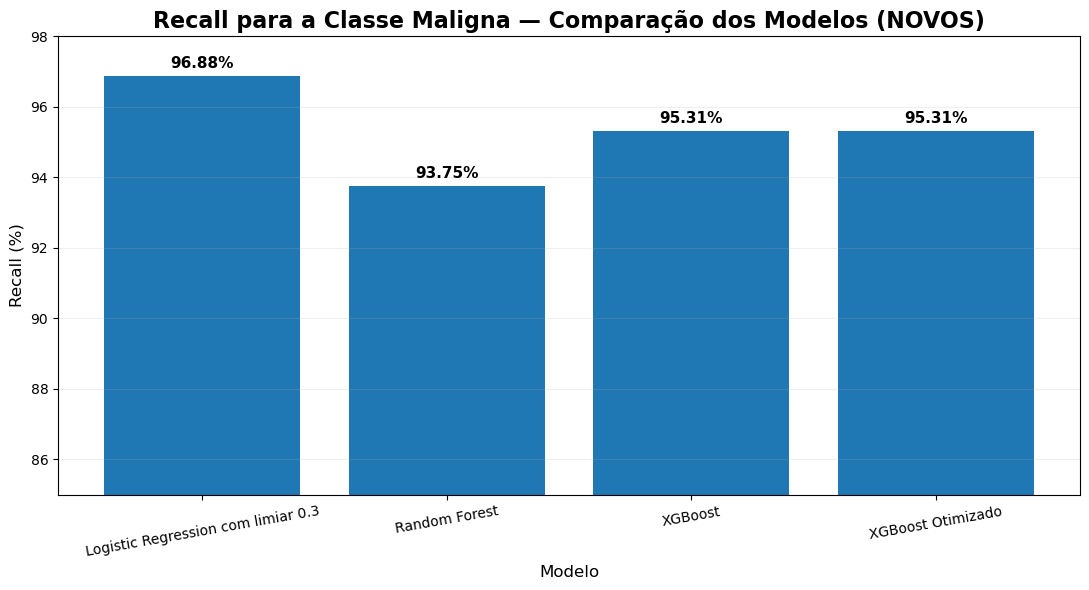

In [265]:
# ============================================================
# RECALL DA CLASSE MALIGNA (1)
# ============================================================

nome_modelos = [
    "Logistic Regression com limiar 0.3",
    "Random Forest",
    "XGBoost",
    "XGBoost Otimizado"
]

recall = [
    96.88,
    93.75, 
    95.31, 
    95.31
]

# ============================================================
# GRÁFICO
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.bar(
    nome_modelos,
    recall
)

# ============================================================
# VALORES NAS BARRAS
# ============================================================

for barra, valor in zip(barras, recall):

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.15,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# ============================================================
# CONFIGURAÇÕES
# ============================================================

ax.set_title(
    "Recall para a Classe Maligna — Comparação dos Modelos (NOVOS)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Recall (%)",
    fontsize=12
)

ax.set_xlabel(
    "Modelo",
    fontsize=12
)

# Começar o eixo em 85 para destacar melhor as diferenças
ax.set_ylim(85, 98)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.xticks(
    rotation=10
)


plt.tight_layout()
plt.show()

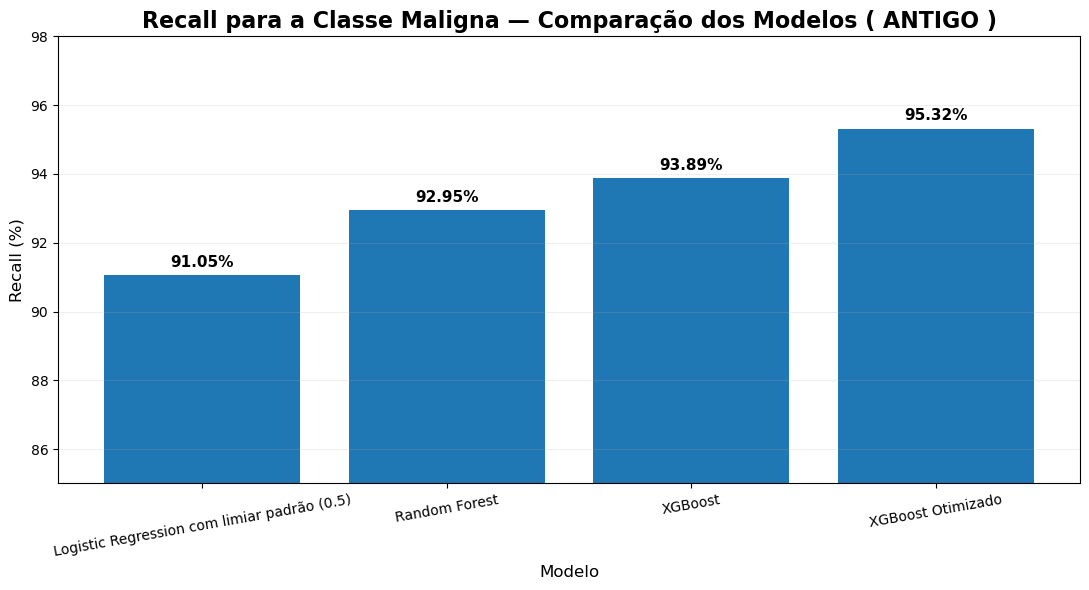

In [257]:
# RECALL DA CLASSE MALIGNA (1)
nome_modelos = [
    "Logistic Regression com limiar padrão (0.5)",
    "Random Forest",
    "XGBoost",
    "XGBoost Otimizado"
]

recall = [
    91.05,
    92.95,
    93.89,
    95.32
]

# GRÁFICO
fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.bar(
    nome_modelos,
    recall
)

# VALORES NAS BARRAS
for barra, valor in zip(barras, recall):

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.15,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# CONFIGURAÇÕES
ax.set_title(
    "Recall para a Classe Maligna — Comparação dos Modelos ( ANTIGO )",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Recall (%)",
    fontsize=12
)

ax.set_xlabel(
    "Modelo",
    fontsize=12
)

# Começar o eixo em 85 para destacar melhor as diferenças
ax.set_ylim(85, 98)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.show()

# **CONCLUSÃO GERAL DO PROJETO**

O objetivo foi comparar modelos de Machine Learning para classificar tumores como benignos ou malignos, priorizando a detecção dos casos malignos (recall). O projeto combinou validação cruzada estratificada, interpretação por blocos de variáveis, teste de McNemar e ajuste do limiar de decisão.

## **1. Tamanho e concavidade se complementam**
Nos três modelos, combinar os blocos de tamanho e de concavidade melhorou o AUC em cerca de 0,01 a 0,04 em relação a cada bloco isolado. Como essas diferenças são próximas dos desvios padrão, o resultado sugere a complementaridade, mas não a prova. O retreino mostrou que o modelo ainda chega a AUC de 0,98 sem o bloco de concavidade, porque as demais variáveis carregam informação parecida. Pela forte colinearidade (VIF de até 3995), a leitura segura é por bloco, não por variável isolada.

## **2. Os modelos não se distinguem estatisticamente**
O teste exato de McNemar, com limiar 0,5 e 171 pacientes, não encontrou diferença entre XGBoost e Regressão Logística (p = 0,6875) nem entre Random Forest e Regressão Logística (p = 1,0). Isso indica ausência de evidência de diferença, e não prova de equivalência: com poucas discordâncias o teste tem baixo poder. A Regressão Logística foi escolhida pela simplicidade e pela interpretabilidade, não por superioridade estatística.

## **3. Ajuste do limiar de decisão**
O limiar foi escolhido apenas com o treino, por validação cruzada: baixar de 0,5 para 0,3 reduziu os malignos perdidos de 7 para 4 (de 148), ao custo de 10 falsos alarmes (de 250). No teste, foi usado uma única vez para confirmar: os malignos perdidos caíram de 4 para 2 (recall de 93,75% para 96,88%), mantendo 1 falso alarme.

| Modelo (teste, 64 malignos) | Limiar | FN | FP | Recall | Precisão |
|---|---|---|---|---|---|
| Regressão Logística | 0,5 | 4 | 1 | 93,75% | 98,36% |
| **Regressão Logística** | **0,3** | **2** | **1** | **96,88%** | **98,41%** |
| Random Forest | 0,5 | 4 | 0 | 93,75% | 100% |
| XGBoost | 0,5 | 3 | 0 | 95,31% | 100% |
| XGBoost otimizado | 0,5 | 3 | 0 | 95,31% | 100% |

O ganho do limiar é de 2 pacientes. O intervalo de confiança de 95% (Wilson) do recall da LR a 0,3 vai de cerca de 89% a 99%, e o do XGBoost, de 87% a 98%: eles se sobrepõem, então o teste não permite afirmar que um é melhor que o outro. O XGBoost otimizado empatou com o padrão no teste, em linha com a validação cruzada, onde o ganho de recall ficou dentro do ruído.

## **Modelo final**
**Regressão Logística (StandardScaler) com limiar 0,3.** A escolha se baseia na interpretabilidade do sentido e do bloco de variáveis, no baixo custo computacional, na facilidade de manutenção e no recall competitivo.

## **Limitações**
- O teste tem 64 malignos: trocar 1 ou 2 pacientes muda o recall em 1,6 a 3,1 pontos percentuais.
- O limiar 0,3 se apoia em poucos erros na validação cruzada (4 a 7 malignos perdidos), então a evidência a favor dele é moderada.
- Os coeficientes individuais são instáveis (colinearidade e intervalos de confiança sobrepostos).
- O limiar do XGBoost não foi ajustado, então a comparação com a LR a 0,3 não é totalmente simétrica.
- Os hiperparâmetros do XGBoost foram escolhidos com os dados inteiros, o que deixa o resultado otimista.
- Projeto educacional, sem validação clínica. Não deve ser usado para diagnóstico real.